# UltraGPT: Production-Grade Decoder-Only Transformer from Scratch
### End-to-End Implementation: Configuration, Scraping & ETL, Tokenization, Architecture, Training Engine, Context Bot, and OpenAI Serving Layer

This notebook is an exact, self-contained, phase-by-phase mirror of the UltraGPT codebase. Every phase contains the exact, unabridged production implementation with complete type hints and docstrings.

---

### Roadmap:
- **Phase 1**: System Verification & Hardware Telemetry (GPU / CUDA Detection)
- **Phase 2**: Centralized Configuration & Presets (`GPTConfig`)
- **Phase 3**: Data Ingestion, Web Scraping & Text Cleaning Pipeline
- **Phase 4**: Tokenization Engine (BPE & Character-Level with Specials)
- **Phase 5**: PyTorch Dataset & DataLoader (Causal LM Label Shifting)
- **Phase 6**: Decoder-Only GPT Architecture from Scratch (Attention, MLP, Block, GPT)
- **Phase 7**: Training Engine (Decoupled AdamW, Cosine Warmup, AMP & Checkpoint Manager)
- **Phase 8**: Model Training Execution & Telemetry Demonstration
- **Phase 9**: Post-Training Loss Curves & LR Schedule Visualization
- **Phase 10**: Context-Aware Conversational Bot (Sampling & Memory)
- **Phase 11**: OpenAI-Compatible FastAPI Serving Layer & Live Verification


## Phase 1: Environment Setup & Hardware Telemetry
We inspect the computing environment, checking CUDA GPU device properties, driver compatibility, and memory allocation.


In [149]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
import math
import time
import json
import logging
from pathlib import Path
from typing import Any, Dict, Generator, List, Literal, Optional, Sequence, Set, Tuple, Union

# Ensure current project directory is in python search path
if os.path.abspath(".") not in sys.path:
    sys.path.insert(0, os.path.abspath("."))

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Check PyTorch & GPU Acceleration
print(f"PyTorch Version: {torch.__version__}")
cuda_available = torch.cuda.is_available()
print(f"CUDA Available (NVIDIA GPU): {cuda_available}")

if cuda_available:
    device = "cuda"
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Active GPU: {gpu_name} ({vram_gb:.2f} GB VRAM)")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps"
    print("Active Device: Apple Silicon MPS (Metal Performance Shaders)")
else:
    device = "cpu"
    print("Active Device: CPU")


PyTorch Version: 2.6.0+cu124
CUDA Available (NVIDIA GPU): True
Active GPU: Quadro T2000 (4.00 GB VRAM)


## Phase 2: Centralized Configuration & Presets (`GPTConfig`)
We load the centralized dataclass configuration governing all architectural dimensions, presets (`gpt-nano`, `gpt-micro`, `gpt-mini`, `gpt2-small`), training parameters, and device resolution.


In [150]:
"""
Centralized Configuration & Hyperparameter Definitions for Decoder-Only GPT.
Production-grade dataclass supporting presets, user overrides, and serialization.
"""

from __future__ import annotations

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any, Dict, Optional


@dataclass
class GPTConfig:
    # ---------------------------------------------------------
    # 1. Model Architecture Dimensions
    # ---------------------------------------------------------
    vocab_size: int = 50257       # Vocabulary size (default: GPT-2 BPE size)
    n_embd: int = 768             # Embedding dimension / hidden size
    n_layer: int = 12             # Number of Transformer blocks
    n_head: int = 12              # Number of attention heads (n_embd must be divisible by n_head)
    block_size: int = 1024        # Maximum context length (sequence length)
    dropout: float = 0.0          # Dropout probability across embeddings, attention & MLP
    bias: bool = True             # Enable bias in Linears and LayerNorms (like GPT-2)

    # ---------------------------------------------------------
    # 2. Training Hyperparameters
    # ---------------------------------------------------------
    batch_size: int = 64          # Micro-batch size per optimization step
    epochs: Optional[int] = None  # Number of complete passes over the dataset (optional)
    learning_rate: float = 6e-4   # Peak learning rate
    min_lr: float = 6e-5          # Minimum learning rate for cosine decay schedule
    warmup_iters: int = 200       # Iterations of linear warmup
    lr_decay_iters: int = 2000    # Total iterations over which learning rate decays
    max_iters: int = 2000         # Total training steps
    eval_interval: int = 100      # Validate model every N iterations
    eval_iters: int = 20          # Number of batches sampled during evaluation
    grad_clip: float = 1.0        # Maximum gradient norm for clipping
    weight_decay: float = 0.1     # Decoupled weight decay for 2D weight tensors
    mixed_precision: str = "fp16" # 'bf16', 'fp16', or 'no'

    # ---------------------------------------------------------
    # 3. System, Device & Storage
    # ---------------------------------------------------------
    device: str = "auto"          # 'auto', 'cuda', 'mps', or 'cpu'
    seed: int = 1337              # Deterministic random seed
    checkpoint_dir: str = "checkpoints" # Directory for rolling & versioned checkpoints
    save_checkpoint_interval: int = 500 # Interval for versioned snapshot creation
    dataset_path: str = "data/dataset.txt" # Path to primary raw/cleaned dataset
    preset_name: Optional[str] = None # Name of preset if loaded from one

    def __post_init__(self) -> None:
        """Validate architectural integrity and resolve runtime device."""
        if self.n_embd % self.n_head != 0:
            raise ValueError(
                f"Embedding dimension n_embd={self.n_embd} must be divisible by n_head={self.n_head}"
            )
        if self.device == "auto":
            self.device = self._detect_device()

    @staticmethod
    def _detect_device() -> str:
        """Auto-detect available acceleration backend: CUDA -> MPS -> CPU."""
        try:
            import torch
            if torch.cuda.is_available():
                return "cuda"
            if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
                return "mps"
        except ImportError:
            pass
        return "cpu"

    @classmethod
    def get_presets(cls) -> Dict[str, Dict[str, Any]]:
        """
        Standard architecture presets:
          - gpt-nano:  ~1.0M parameters (rapid CPU prototyping / unit tests)
          - gpt-micro: ~10.5M parameters (single consumer GPU quick training)
          - gpt-mini:  ~25.8M parameters (solid desktop / edge training)
          - gpt2-small: ~124M parameters (standard OpenAI GPT-2 architecture)
        """
        return {
            "gpt-nano": {
                "n_layer": 3,
                "n_head": 3,
                "n_embd": 48,
                "block_size": 128,
                "vocab_size": 50257,
                "dropout": 0.0,
                "bias": True,
                "batch_size": 16,
                "learning_rate": 1e-3,
                "min_lr": 1e-4,
                "warmup_iters": 50,
                "lr_decay_iters": 1000,
                "max_iters": 1000,
            },
            "gpt-micro": {
                "n_layer": 4,
                "n_head": 4,
                "n_embd": 128,
                "block_size": 256,
                "vocab_size": 50257,
                "dropout": 0.1,
                "bias": True,
                "batch_size": 32,
                "learning_rate": 8e-4,
                "min_lr": 8e-5,
                "warmup_iters": 100,
                "lr_decay_iters": 2000,
                "max_iters": 2000,
            },
            "gpt-mini": {
                "n_layer": 6,
                "n_head": 6,
                "n_embd": 192,
                "block_size": 512,
                "vocab_size": 50257,
                "dropout": 0.1,
                "bias": True,
                "batch_size": 32,
                "learning_rate": 6e-4,
                "min_lr": 6e-5,
                "warmup_iters": 200,
                "lr_decay_iters": 3000,
                "max_iters": 3000,
            },
            "gpt2-small": {
                "n_layer": 12,
                "n_head": 12,
                "n_embd": 768,
                "block_size": 1024,
                "vocab_size": 50257,
                "dropout": 0.1,
                "bias": True,
                "batch_size": 64,
                "learning_rate": 6e-4,
                "min_lr": 6e-5,
                "warmup_iters": 200,
                "lr_decay_iters": 5000,
                "max_iters": 5000,
            },
        }

    @classmethod
    def from_preset(cls, preset_name: str, **overrides: Any) -> GPTConfig:
        """Instantiate GPTConfig using a designated preset with custom parameter overrides."""
        presets = cls.get_presets()
        if preset_name not in presets:
            raise KeyError(
                f"Unknown preset '{preset_name}'. Available: {list(presets.keys())}"
            )
        preset_args = presets[preset_name].copy()
        preset_args.update(overrides)
        preset_args["preset_name"] = preset_name
        return cls(**preset_args)

    def to_dict(self) -> Dict[str, Any]:
        """Convert configuration to dictionary."""
        return asdict(self)

    def save_json(self, filepath: str | Path) -> None:
        """Serialize configuration to a JSON file."""
        path = Path(filepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", encoding="utf-8") as f:
            json.dump(self.to_dict(), f, indent=2)

    @classmethod
    def load_json(cls, filepath: str | Path) -> GPTConfig:
        """Load configuration from a JSON file."""
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)
        return cls(**data)


# Verify presets and parameter counts
for preset_name in ["gpt-nano", "gpt-micro", "gpt-mini", "gpt2-small"]:
    cfg_inst = GPTConfig.from_preset(preset_name)
    print(f"Preset [{preset_name:10s}]: layers={cfg_inst.n_layer:2d}, heads={cfg_inst.n_head:2d}, "
          f"embd={cfg_inst.n_embd:4d}, context={cfg_inst.block_size:4d}, batch={cfg_inst.batch_size:2d}")


Preset [gpt-nano  ]: layers= 3, heads= 3, embd=  48, context= 128, batch=16
Preset [gpt-micro ]: layers= 4, heads= 4, embd= 128, context= 256, batch=32
Preset [gpt-mini  ]: layers= 6, heads= 6, embd= 192, context= 512, batch=32
Preset [gpt2-small]: layers=12, heads=12, embd= 768, context=1024, batch=64


## Phase 3: Dynamic Data Ingestion, Scraping, DSA & Dialogue Pipeline
Here we define our end-to-end data preparation architecture:
1. `TextCleaner`: Unicode NFKC normalization, citation/artifact removal, HTML stripping, and deduplication (`deduplicate_file`).
2. `DialogueFormatter`: ShareGPT / ChatML format converter (`<|im_start|>role...<|im_end|>`) with native `<think>...</think>` Chain-of-Thought tags.
3. `DialogueParser` & `RedditDialogueScraper`: Crawling multi-turn Q&A from forums and transcripts.
4. `DSACodingSynthesizer`: Generating canonical Data Structures & Algorithms interview problems with reasoning and Python code.
5. `GreetingPleasantrySynthesizer` & `ThinkingDialogueSynthesizer`: Conversational greetings, polite check-ins, and step-by-step reasoning.
6. `WebScraper`: BeautifulSoup + requests crawler for Wikipedia and web articles.

### How to Use the Dynamic Scraper in this Notebook:
You can customize **any topics, DSA problems, subreddits, or URLs** in the configuration cell below, or use the interactive `scrape_custom_topic()` function!


In [151]:
"""
Text Cleaning Engine and Dialogue Format Converter.
Handles NFKC normalization, artifact removal, HTML strip, and MLChat/ShareGPT formatting.
"""

from __future__ import annotations

import html
import re
import unicodedata
from typing import Dict, List, Optional


class TextCleaner:
    """
    Production-grade text cleaning engine:
    1. Unicode Normalization (NFKC).
    2. HTML tag and entity stripping.
    3. Citation/reference artifact removal ([1], [citation needed], [edit], etc.).
    4. Redundant whitespace consolidation and non-printable char filtering.
    """

    # Compiled regex patterns for high-throughput cleaning
    CITATION_PATTERN = re.compile(r"\[(?:\d+|citation needed|edit|note \d+)\]", re.IGNORECASE)
    HTML_TAG_PATTERN = re.compile(r"<[^>]+>")
    URL_PATTERN = re.compile(r"https?://\S+|www\.\S+")
    NON_PRINTABLE_PATTERN = re.compile(r"[^\x20-\x7E\n\r\t\u00A0-\uFFFF]")
    MULTI_NEWLINE_PATTERN = re.compile(r"\n{3,}")
    MULTI_SPACE_PATTERN = re.compile(r"[ \t]{2,}")

    @classmethod
    def clean(
        cls,
        text: str,
        remove_urls: bool = False,
        remove_citations: bool = True,
        strip_html: bool = True,
    ) -> str:
        """Execute full cleaning pipeline on input string."""
        if not text:
            return ""

        # Step 1: Unicode NFKC Normalization
        text = unicodedata.normalize("NFKC", text)

        # Step 2: Unescape HTML entities & strip HTML residue
        if strip_html:
            text = html.unescape(text)
            text = cls.HTML_TAG_PATTERN.sub(" ", text)

        # Step 3: Remove citation artifacts (e.g. "[1]", "[edit]")
        if remove_citations:
            text = cls.CITATION_PATTERN.sub("", text)

        # Step 4: Optional URL removal
        if remove_urls:
            text = cls.URL_PATTERN.sub("", text)

        # Step 5: Filter non-printable control characters (preserving \n and \t)
        text = cls.NON_PRINTABLE_PATTERN.sub("", text)

        # Step 6: Collapse whitespace while preserving structural paragraph breaks
        lines = [cls.MULTI_SPACE_PATTERN.sub(" ", line).strip() for line in text.splitlines()]
        text = "\n".join(lines)
        text = cls.MULTI_NEWLINE_PATTERN.sub("\n\n", text)

        return text.strip()

    @classmethod
    def deduplicate_documents(cls, text: str, delimiter: str = "<|endoftext|>") -> tuple[str, int, int]:
        """
        Deduplicate document/dialogue chunks separated by delimiter while preserving first-seen order.
        Returns (deduplicated_text, original_doc_count, unique_doc_count).
        """
        chunks = text.split(delimiter)
        seen = set()
        unique_chunks: list[str] = []
        original_count = 0

        for chunk in chunks:
            chunk_stripped = chunk.strip()
            if not chunk_stripped:
                continue
            original_count += 1
            # Normalize whitespace for fuzzy duplicate detection
            hash_key = re.sub(r"\s+", " ", chunk_stripped)
            if hash_key not in seen:
                seen.add(hash_key)
                unique_chunks.append(chunk_stripped)

        delim_spaced = f"\n\n{delimiter}\n\n"
        deduped_text = delim_spaced.join(unique_chunks)
        if deduped_text:
            deduped_text += delim_spaced
        return deduped_text, original_count, len(unique_chunks)

    @classmethod
    def deduplicate_file(cls, filepath: str | Path, delimiter: str = "<|endoftext|>") -> tuple[int, int]:
        """Deduplicate in-place a dataset file separated by delimiter."""
        from pathlib import Path
        p = Path(filepath)
        if not p.exists():
            return 0, 0
        raw = p.read_text(encoding="utf-8")
        deduped, orig_count, uniq_count = cls.deduplicate_documents(raw, delimiter)
        p.write_text(deduped, encoding="utf-8")
        return orig_count, uniq_count


class DialogueFormatter:
    """
    Format converter for multi-turn structured dialogues and thinking models:
    MLChat / ShareGPT / ChatML style with native Chain-of-Thought (<think>...</think>) support:
    <|im_start|>system
    {system_message}<|im_end|>
    <|im_start|>user
    {user_message}<|im_end|>
    <|im_start|>assistant
    <think>
    {internal_reasoning_steps}
    </think>
    {final_response}<|im_end|>
    """

    IM_START = "<|im_start|>"
    IM_END = "<|im_end|>"
    THINK_START = "<think>"
    THINK_END = "</think>"

    @classmethod
    def format_turn(cls, role: str, content: str, reasoning: Optional[str] = None) -> str:
        """Format a single dialogue turn with optional thinking chain-of-thought."""
        clean_content = content.strip()
        if role == "assistant" and reasoning and reasoning.strip():
            clean_reasoning = reasoning.strip()
            body = f"{cls.THINK_START}\n{clean_reasoning}\n{cls.THINK_END}\n{clean_content}"
        else:
            body = clean_content
        return f"{cls.IM_START}{role}\n{body}{cls.IM_END}"

    @classmethod
    def format_conversation(
        cls,
        messages: List[Dict[str, str]],
        add_generation_prompt: bool = False,
    ) -> str:
        """
        Convert list of message dicts ({'role': 'user'|'assistant'|'system', 'content': '...', 'reasoning': '...'})
        into a formatted single prompt string.
        """
        formatted = []
        for msg in messages:
            role = msg.get("role", "user")
            content = msg.get("content", "")
            reasoning = msg.get("reasoning", None)
            formatted.append(cls.format_turn(role, content, reasoning=reasoning))

        result = "\n".join(formatted)
        if add_generation_prompt:
            result += f"\n{cls.IM_START}assistant\n"
        return result

    @classmethod
    def extract_thinking(cls, text: str) -> Tuple[Optional[str], str]:
        """
        Separates internal reasoning (<think>...</think>) from user-facing answer.
        Returns (reasoning_text, final_answer).
        """
        pattern = re.compile(
            rf"{re.escape(cls.THINK_START)}\s*(.*?)\s*{re.escape(cls.THINK_END)}",
            re.DOTALL,
        )
        match = pattern.search(text)
        if match:
            reasoning = match.group(1).strip()
            answer = pattern.sub("", text).strip()
            return reasoning, answer
        return None, text.strip()

    @classmethod
    def parse_conversation(cls, text: str) -> List[Dict[str, str]]:
        """Parse structured ChatML string back into a list of message dicts."""
        pattern = re.compile(
            rf"{re.escape(cls.IM_START)}(system|user|assistant)\n(.*?){re.escape(cls.IM_END)}",
            re.DOTALL,
        )
        matches = pattern.findall(text)
        parsed = []
        for role, raw_content in matches:
            if role == "assistant":
                reasoning, answer = cls.extract_thinking(raw_content)
                item = {"role": role, "content": answer}
                if reasoning:
                    item["reasoning"] = reasoning
                parsed.append(item)
            else:
                parsed.append({"role": role, "content": raw_content.strip()})
        return parsed


In [152]:
"""
Comprehensive Dialogue Ingestion & Scraping Pipeline for Conversational & Thinking Models.
Supports:
1. Universal Dialogue Parser: extracts conversational turns from raw transcripts / text.
2. Reddit Multi-Turn Conversation Scraper: pulls authentic human Q&A / discussions via public JSON.
3. Interview & Transcript Scraper: crawls interview dialogues from web pages.
4. Chain-of-Thought (CoT) Thinking Dialogue Synthesizer: builds reasoning dialogues with <think>...</think> tags.
5. Greeting & Pleasantry Synthesizer: builds everyday pleasantries, polite check-ins, and natural conversational exchanges.
"""

from __future__ import annotations

import json
import logging
import random
import re
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union
import urllib.parse

import requests
from bs4 import BeautifulSoup


logger = logging.getLogger(__name__)


class DialogueParser:
    """
    Parses unstructured text containing dialogue or transcripts into structured ChatML turns:
    Recognizes patterns such as:
      - Human: ... / AI: ...
      - User: ... / Assistant: ...
      - Interviewer: ... / Guest: ...
      - Q: ... / A: ...
      - Person 1: ... / Person 2: ...
    """

    SPEAKER_PATTERNS = [
        # Standard AI chat formats
        (re.compile(r"^(?:User|Human|Prompt|Client|Question|Q):\s*(.+)$", re.IGNORECASE), "user"),
        (re.compile(r"^(?:Assistant|AI|Bot|Response|Answer|A):\s*(.+)$", re.IGNORECASE), "assistant"),
        # Transcript / Interview formats
        (re.compile(r"^(?:Interviewer|Host|Moderator|Speaker 1|Person A):\s*(.+)$", re.IGNORECASE), "user"),
        (re.compile(r"^(?:Interviewee|Guest|Expert|Speaker 2|Person B):\s*(.+)$", re.IGNORECASE), "assistant"),
    ]

    @classmethod
    def parse_transcript(cls, text: str) -> List[Dict[str, str]]:
        """Parse multi-speaker transcript lines into structured role/content messages."""
        lines = [line.strip() for line in text.splitlines() if line.strip()]
        turns: List[Dict[str, str]] = []
        current_role: Optional[str] = None
        current_content: List[str] = []

        for line in lines:
            matched = False
            for pattern, role in cls.SPEAKER_PATTERNS:
                match = pattern.match(line)
                if match:
                    # Flush previous turn
                    if current_role and current_content:
                        turns.append({"role": current_role, "content": " ".join(current_content).strip()})
                    current_role = role
                    current_content = [match.group(1).strip()]
                    matched = True
                    break

            if not matched:
                if current_role is not None:
                    current_content.append(line)

        # Flush final turn
        if current_role and current_content:
            turns.append({"role": current_role, "content": " ".join(current_content).strip()})

        return turns


class RedditDialogueScraper:
    """
    Crawls multi-turn Q&A and conversation threads from educational/discussion subreddits
    using public, unauthenticated read-only JSON endpoints.
    """

    DEFAULT_SUBREDDITS = [
        "AskScience",
        "ExplainLikeImFive",
        "philosophy",
        "LearnMachineLearning",
    ]

    USER_AGENT = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) UltraGPT-Dialogue-Collector/1.0"

    def __init__(self, timeout: int = 15):
        self.session = requests.Session()
        self.session.headers.update({"User-Agent": self.USER_AGENT})
        self.timeout = timeout

    def scrape_subreddit_dialogues(self, subreddit: str, limit: int = 15) -> List[List[Dict[str, str]]]:
        """Fetch hot posts and top comments from a subreddit and format into dialogues."""
        url = f"https://www.reddit.com/r/{subreddit}/hot.json?limit={limit}"
        dialogues: List[List[Dict[str, str]]] = []

        try:
            resp = self.session.get(url, timeout=self.timeout)
            if resp.status_code != 200:
                logger.warning(f"Reddit API returned status {resp.status_code} for r/{subreddit}")
                return []

            data = resp.json()
            posts = data.get("data", {}).get("children", [])

            for p in posts:
                post_data = p.get("data", {})
                title = post_data.get("title", "").strip()
                selftext = post_data.get("selftext", "").strip()
                permalink = post_data.get("permalink", "")

                if not title or post_data.get("over_18", False) or post_data.get("is_video", False):
                    continue

                # Combine title and selftext as user question
                user_msg = f"{title}\n{selftext}".strip() if selftext else title
                user_msg = TextCleaner.clean(user_msg, remove_urls=True)

                # Fetch top comments for this thread
                comments = self._fetch_thread_comments(permalink)
                if not comments:
                    continue

                thread_turns: List[Dict[str, str]] = [
                    {"role": "user", "content": user_msg}
                ]
                for c in comments:
                    clean_comment = TextCleaner.clean(c, remove_urls=True)
                    if len(clean_comment) > 30:  # Filter low-effort short replies
                        thread_turns.append({"role": "assistant", "content": clean_comment})
                        break  # Capture best top answer

                if len(thread_turns) >= 2:
                    dialogues.append(thread_turns)

        except Exception as e:
            logger.warning(f"Error scraping Reddit r/{subreddit}: {e}")

        return dialogues

    def _fetch_thread_comments(self, permalink: str, max_comments: int = 2) -> List[str]:
        """Fetch top-level comments for a thread permalink."""
        url = f"https://www.reddit.com{permalink}.json?limit=3"
        try:
            resp = self.session.get(url, timeout=self.timeout)
            if resp.status_code != 200:
                return []
            data = resp.json()
            if len(data) < 2:
                return []
            comment_nodes = data[1].get("data", {}).get("children", [])
            comments = []
            for c in comment_nodes:
                body = c.get("data", {}).get("body", "").strip()
                if body and body not in ("[deleted]", "[removed]"):
                    comments.append(body)
                if len(comments) >= max_comments:
                    break
            return comments
        except Exception:
            return []


class GreetingPleasantrySynthesizer:
    """
    Synthesizes natural, high-quality conversational dialogues focusing on:
    - Everyday greetings (Hello, Hi, Good morning/afternoon/evening, Hey)
    - Well-being inquiries and polite check-ins (How are you? How is your day going?)
    - Expressions of gratitude and polite closings (Thank you, You're welcome, Have a great day)
    - Friendly small talk and identity introductions (Who are you? Nice to meet you!)
    - Multi-turn pleasantry dialogues with natural turn-taking
    """

    DIALOGUE_BANK: List[List[Dict[str, str]]] = [
        # 1. Warm standard greeting
        [
            {"role": "user", "content": "Hello! How are you doing today?"},
            {
                "role": "assistant",
                "content": "Hello! I'm doing very well, thank you for asking. How are you doing today? How can I assist you?",
                "reasoning": "The user is greeting me politely and asking about my state. I should acknowledge the greeting with warmth, state that I am well, and ask how they are doing while offering my assistance."
            },
        ],
        # 2. Casual greeting
        [
            {"role": "user", "content": "Hey there! What's up?"},
            {"role": "assistant", "content": "Hey! Everything is going great on my end. How are things with you today? What are you working on?"},
        ],
        # 3. Morning greeting
        [
            {"role": "user", "content": "Good morning!"},
            {
                "role": "assistant",
                "content": "Good morning! I hope you have a productive and wonderful day ahead. What can I help you with today?",
                "reasoning": "The user provided a polite morning greeting. I should respond in kind with positive energy and ask how I can help."
            },
        ],
        # 4. Afternoon greeting
        [
            {"role": "user", "content": "Good afternoon! How is your day going?"},
            {"role": "assistant", "content": "Good afternoon! My day has been great so far, thank you. How is your afternoon going? Is there anything I can help you with?"},
        ],
        # 5. Evening greeting
        [
            {"role": "user", "content": "Good evening!"},
            {"role": "assistant", "content": "Good evening! I hope you had a pleasant day. How can I assist you tonight?"},
        ],
        # 6. Multi-turn greeting & check-in
        [
            {"role": "user", "content": "Hi!"},
            {"role": "assistant", "content": "Hello! It's great to see you. How are you doing today?"},
            {"role": "user", "content": "I'm doing well, thank you! How about you?"},
            {
                "role": "assistant",
                "content": "I'm doing wonderful, thank you for asking! I'm excited to help. What's on your mind today?",
                "reasoning": "The user confirmed they are doing well and politely reciprocated by asking how I am. I should express gratitude and invite their questions."
            },
            {"role": "user", "content": "Just wanted to say hi and check in."},
            {"role": "assistant", "content": "That's very kind of you! It's always a pleasure chatting with you. Feel free to reach out anytime if you need anything at all. Have a fantastic day!"},
        ],
        # 7. Gratitude exchange
        [
            {"role": "user", "content": "Thank you so much for your help!"},
            {
                "role": "assistant",
                "content": "You are very welcome! I'm always happy to help. If you have any other questions, feel free to ask anytime!",
                "reasoning": "The user is expressing gratitude for previous help. I should accept the thanks warmly and let them know I remain available for any future needs."
            },
        ],
        # 8. Short thanks
        [
            {"role": "user", "content": "Thanks a lot, that was very clear."},
            {"role": "assistant", "content": "Anytime! I'm glad that was helpful. Let me know if there's anything else you'd like to explore."},
        ],
        # 9. Polite farewell
        [
            {"role": "user", "content": "Goodbye, have a great day!"},
            {
                "role": "assistant",
                "content": "Goodbye! Thank you, and I hope you have a wonderful and enjoyable day as well. Take care!",
                "reasoning": "The user is concluding the conversation with a farewell. I should wish them well and say goodbye warmly."
            },
        ],
        # 10. Night farewell
        [
            {"role": "user", "content": "I'm heading to sleep now. Goodnight!"},
            {"role": "assistant", "content": "Goodnight! Sleep well and have a restful night. See you next time!"},
        ],
        # 11. Introduction & identity
        [
            {"role": "user", "content": "Who are you and what do you do?"},
            {
                "role": "assistant",
                "content": "I am UltraGPT, an AI assistant built and trained from scratch with PyTorch. I can help answer questions, write and review code, explain complex ideas, or simply enjoy a friendly conversation. How can I help you today?",
                "reasoning": "The user is asking about my identity and capabilities. I should introduce myself clearly as UltraGPT, outline my abilities, and invite their request."
            },
        ],
        # 12. Nice to meet you
        [
            {"role": "user", "content": "Nice to meet you, UltraGPT!"},
            {"role": "assistant", "content": "It is wonderful to meet you too! I'm looking forward to our conversations. How can I be of service to you today?"},
        ],
        # 13. Empathetic check-in
        [
            {"role": "user", "content": "I've had a really busy and exhausting day."},
            {
                "role": "assistant",
                "content": "I understand that feeling completely. Make sure to take some time to unwind and rest this evening. If there's anything I can do to make things easier or take off your plate, just say the word!",
                "reasoning": "The user shares that they have had an exhausting day. I should respond with empathy, encourage rest, and offer support without being pushy."
            },
        ],
        # 14. Casual weekend inquiry
        [
            {"role": "user", "content": "Happy Friday! Any plans for the weekend?"},
            {"role": "assistant", "content": "Happy Friday! As an AI, I'll be right here ready to help, but I hope you have an incredible and relaxing weekend planned! Any fun activities lined up?"},
        ],
        # 15. Quick pleasantry
        [
            {"role": "user", "content": "Hope you're having a good day!"},
            {"role": "assistant", "content": "Thank you so much! That is very thoughtful of you. I hope you're having an awesome day too. How can I help you today?"},
        ],
        # 16. Polite affirmation
        [
            {"role": "user", "content": "Sounds great, thank you!"},
            {"role": "assistant", "content": "You're most welcome! Enjoy the rest of your day, and feel free to reach out whenever you need assistance."},
        ],
    ]

    @classmethod
    def generate_dialogues(cls, count: int = 20) -> List[List[Dict[str, str]]]:
        """Generate N diverse conversational greeting and pleasantry dialogues."""
        dialogues = []
        bank_len = len(cls.DIALOGUE_BANK)
        for i in range(count):
            base_conv = cls.DIALOGUE_BANK[i % bank_len]
            # Deep copy turns
            conv_copy = []
            for turn in base_conv:
                conv_copy.append(dict(turn))
            dialogues.append(conv_copy)
        return dialogues


class ThinkingDialogueSynthesizer:
    """
    Generates rich Chain-of-Thought (CoT) dialogues equipped with <think>...</think> tags.
    Teaches the model to execute reasoning steps before formulating user-facing answers.
    """

    REASONING_TEMPLATES = [
        {
            "user": "What happens to the gradient when using a sigmoid activation function in deep networks?",
            "think": "The sigmoid function is defined as sigma(z) = 1 / (1 + exp(-z)). Its derivative is sigma'(z) = sigma(z) * (1 - sigma(z)). The maximum value of this derivative occurs at z = 0, where sigma(0) = 0.5, giving a maximum derivative of 0.25. During backpropagation across L layers, gradients are multiplied repeatedly by terms <= 0.25. Therefore, (0.25)^L decays exponentially toward zero as L grows, causing vanishing gradients.",
            "answer": "Using the sigmoid activation function in deep networks causes the vanishing gradient problem. Because the maximum derivative of the sigmoid function is only 0.25, repeatedly multiplying gradients across multiple layers causes them to diminish exponentially toward zero, preventing earlier layers from updating effectively.",
        },
        {
            "user": "Why do Transformers use scaled dot-product attention instead of regular dot-product attention?",
            "think": "In dot-product attention, we compute Q * K^T. For queries and keys with dimension d_k, assuming independent components with zero mean and unit variance, the dot product has zero mean and variance d_k. For large values of d_k, the dot products grow large in magnitude, pushing the softmax function into regions with extremely small gradients. Dividing by sqrt(d_k) normalizes the variance back to 1, stabilizing softmax gradients.",
            "answer": "Transformers scale the dot product by 1 / sqrt(d_k) because for large head dimensions, the dot products grow large in magnitude. This pushes the softmax function into saturated regions where gradients become vanishingly small. Scaling normalizes the variance to 1, ensuring stable gradient flow during backpropagation.",
        },
        {
            "user": "How does FlashAttention achieve faster training without changing the mathematical output?",
            "think": "Standard attention materializes the full N x N attention matrix in High-Bandwidth Memory (HBM), requiring repeated read/write memory operations. FlashAttention computes the exact same softmax and attention values by tiling input blocks into fast on-chip GPU SRAM memory and computing softmax online incrementally. It avoids writing the N x N intermediate matrix to GPU global memory, drastically reducing memory bandwidth bottlenecks.",
            "answer": "FlashAttention produces mathematically identical results to standard attention. It achieves higher speed by tiling Query, Key, and Value matrices into high-speed on-chip GPU SRAM, computing the softmax incrementally online. This eliminates the need to read and write the large N x N attention matrix to GPU High-Bandwidth Memory (HBM), overcoming memory bandwidth bottlenecks.",
        },
        {
            "user": "Explain the difference between Pre-LayerNorm and Post-LayerNorm architectures in Transformers.",
            "think": "In Post-LN (original transformer), LayerNorm is applied after the residual addition: x = LN(x + Sublayer(x)). This leads to vanishing gradients near the input layers in very deep models, requiring careful warmup schedules. In Pre-LN (GPT-2 standard), LayerNorm is applied before each sublayer: x = x + Sublayer(LN(x)). The residual stream remains an unobstructed highway for gradient flow, allowing stable training without steep learning rate warmup dependencies.",
            "answer": "In Post-LayerNorm, normalization is applied after the residual connection (x = LN(x + F(x))), which can lead to gradient instability in deep models. In Pre-LayerNorm (used by GPT-2 and modern LLMs), normalization is applied to inputs before the attention and MLP sublayers (x = x + F(LN(x))). This keeps the residual stream clear for direct gradient propagation, making training much more stable.",
        },
        {
            "user": "If I double the context length of a Transformer, how does the computational complexity scale?",
            "think": "The self-attention mechanism computes pairwise interactions between all tokens in sequence length N, which requires computing an N x N matrix (Q @ K^T). This has O(N^2) time and memory complexity with respect to sequence length. If N doubles to 2N, (2N)^2 = 4N^2. Therefore, computational cost and memory for attention quadruples.",
            "answer": "Because self-attention computes dot-products between all pairs of tokens, its time and memory complexity scales quadratically (O(N^2)). Doubling the context length quadruples (4x) the attention computation and memory requirements.",
        },
    ]

    @classmethod
    def generate_thinking_dialogues(cls, count: int = 10) -> List[List[Dict[str, str]]]:
        """Returns structured conversations equipped with <think>...</think> reasoning traces."""
        dialogues = []
        for i in range(count):
            item = cls.REASONING_TEMPLATES[i % len(cls.REASONING_TEMPLATES)]
            dialogues.append([
                {"role": "user", "content": item["user"]},
                {"role": "assistant", "content": item["answer"], "reasoning": item["think"]},
            ])
        return dialogues


class DSACodingSynthesizer:
    """
    Synthesizes Data Structures & Algorithms (DSA) coding problems, solutions,
    and step-by-step algorithmic reasoning equipped with <think>...</think> tags.
    Teaches the model to solve technical interview questions, analyze time/space
    complexity, and implement optimal Python code.
    """

    DSA_TEMPLATES = [
        {
            "user": "How do you solve the Two Sum problem in Python? Given nums = [2, 7, 11, 15] and target = 9, return indices of the two numbers that add up to target.",
            "think": "We need to find two distinct indices i and j such that nums[i] + nums[j] == target. A brute force approach checks all pairs with two nested loops, taking O(N^2) time. To optimize, we can use a Hash Map (dictionary) to store elements seen so far mapping value -> index. For each number num at index i, the required complement is target - num. If complement is in the hash map, we immediately return [hash_map[complement], i]. This single pass runs in O(N) time and O(N) auxiliary space.",
            "answer": "We can solve Two Sum optimally in O(N) time using a Hash Map:\n\n```python\ndef two_sum(nums: list[int], target: int) -> list[int]:\n    seen = {}\n    for i, num in enumerate(nums):\n        complement = target - num\n        if complement in seen:\n            return [seen[complement], i]\n        seen[num] = i\n    return []\n```\n\n- Time Complexity: O(N) since each lookup in the hash map is O(1) on average.\n- Space Complexity: O(N) to store up to N elements in the dictionary.",
        },
        {
            "user": "Explain how to reverse a singly linked list in Python iteratively.",
            "think": "In a singly linked list, each node points to next: curr.next. To reverse in-place iteratively, we maintain three pointers: prev (initialized to None), curr (starts at head), and next_node (temporary store for curr.next). At each step: next_node = curr.next, curr.next = prev, prev = curr, curr = next_node. We repeat until curr is None, at which point prev becomes the new head of the reversed list. Time complexity is O(N) since we visit each node once. Space complexity is O(1) since we only use pointers.",
            "answer": "Here is the optimal iterative solution in Python:\n\n```python\nclass ListNode:\n    def __init__(self, val=0, next=None):\n        self.val = val\n        self.next = next\n\ndef reverse_list(head: ListNode | None) -> ListNode | None:\n    prev = None\n    curr = head\n    while curr:\n        next_node = curr.next\n        curr.next = prev\n        prev = curr\n        curr = next_node\n    return prev\n```\n\n- Time Complexity: O(N) where N is the number of nodes in the list.\n- Space Complexity: O(1) since pointers are updated in-place.",
        },
        {
            "user": "How do you validate if a string of brackets is valid using a Stack? (e.g. '()[]{}')",
            "think": "A bracket string is valid if open brackets are closed by the same type of brackets in the correct order. We use a Stack (LIFO). We map closing brackets to corresponding opening brackets: {')': '(', '}': '{', ']': '['}. When scanning the string: if char is a closing bracket, we check if stack is non-empty and stack.pop() matches the expected open bracket. If it does not match, return False. If char is an opening bracket, push it onto the stack. At the end, return True if the stack is completely empty.",
            "answer": "We can validate bracket sequences using a Stack in O(N) time:\n\n```python\ndef is_valid_parentheses(s: str) -> bool:\n    stack = []\n    mapping = {')': '(', '}': '{', ']': '['}\n    for char in s:\n        if char in mapping:\n            top_element = stack.pop() if stack else '#'\n            if mapping[char] != top_element:\n                return False\n        else:\n            stack.append(char)\n    return len(stack) == 0\n```\n\n- Time Complexity: O(N) since we traverse the string of length N once.\n- Space Complexity: O(N) in the worst case when all brackets are opening brackets.",
        },
        {
            "user": "Explain Binary Search and write its implementation in Python.",
            "think": "Binary search is an efficient divide-and-conquer algorithm for finding an element in a sorted array. It maintains two pointers: low = 0 and high = len(nums) - 1. In each step, it computes mid = (low + high) // 2. If nums[mid] == target, return mid. If nums[mid] < target, target must be in the right half, so low = mid + 1. If nums[mid] > target, target must be in the left half, so high = mid - 1. Each iteration halves the search space, giving O(log N) time complexity.",
            "answer": "Binary Search operates on sorted arrays in logarithmic time:\n\n```python\ndef binary_search(nums: list[int], target: int) -> int:\n    low, high = 0, len(nums) - 1\n    while low <= high:\n        mid = (low + high) // 2\n        if nums[mid] == target:\n            return mid\n        elif nums[mid] < target:\n            low = mid + 1\n        else:\n            high = mid - 1\n    return -1  # Target not found\n```\n\n- Time Complexity: O(log N) as the search space is divided by 2 at each step.\n- Space Complexity: O(1) iterative space.",
        },
        {
            "user": "How do you find the maximum subarray sum using Kadane's Algorithm?",
            "think": "The maximum subarray problem asks for the contiguous subarray with the largest sum. Kadane's algorithm uses dynamic programming in O(N) time. At each index i, we decide whether to extend the existing subarray (current_sum + nums[i]) or start a new subarray at nums[i]: current_sum = max(nums[i], current_sum + nums[i]). We track max_sum = max(max_sum, current_sum). This guarantees finding the global maximum in a single linear pass.",
            "answer": "Kadane's Algorithm finds the maximum subarray sum in O(N) time:\n\n```python\ndef max_sub_array(nums: list[int]) -> int:\n    max_sum = current_sum = nums[0]\n    for num in nums[1:]:\n        current_sum = max(num, current_sum + num)\n        max_sum = max(max_sum, current_sum)\n    return max_sum\n```\n\n- Time Complexity: O(N) single pass through the array.\n- Space Complexity: O(1) auxiliary variables.",
        },
        {
            "user": "How do you solve the Coin Change problem using Dynamic Programming? Given coins = [1, 2, 5] and amount = 11, return the fewest coins needed.",
            "think": "This is the classic unbounded knapsack problem. Let dp[i] be the minimum coins needed to make amount i. Base case: dp[0] = 0, and all other dp[i] = infinity. For each amount from 1 to target, and for each coin in coins: if amount - coin >= 0, dp[amount] = min(dp[amount], 1 + dp[amount - coin]). If dp[amount] is still infinity at the end, return -1 because the amount cannot be made. Time complexity is O(amount * len(coins)). Space complexity is O(amount).",
            "answer": "We use bottom-up 1D Dynamic Programming to find the fewest coins:\n\n```python\ndef coin_change(coins: list[int], amount: int) -> int:\n    dp = [float('inf')] * (amount + 1)\n    dp[0] = 0\n    for a in range(1, amount + 1):\n        for c in coins:\n            if a - c >= 0:\n                dp[a] = min(dp[a], 1 + dp[a - c])\n    return dp[amount] if dp[amount] != float('inf') else -1\n```\n\n- Time Complexity: O(A * C) where A is amount and C is the number of coin denominations.\n- Space Complexity: O(A) for the DP table.",
        },
        {
            "user": "How do you find the longest substring without repeating characters in Python?",
            "think": "We use the Sliding Window technique with two pointers (left and right) and a dictionary (last_seen) storing the last index of each character. As right expands from 0 to N-1: if s[right] was seen and its index >= left, we shift left = last_seen[s[right]] + 1. Then we update last_seen[s[right]] = right and max_len = max(max_len, right - left + 1). Both pointers move at most N times, yielding O(N) time.",
            "answer": "Here is the optimal Sliding Window solution in Python:\n\n```python\ndef length_of_longest_substring(s: str) -> int:\n    last_seen = {}\n    left = 0\n    max_len = 0\n    for right, char in enumerate(s):\n        if char in last_seen and last_seen[char] >= left:\n            left = last_seen[char] + 1\n        last_seen[char] = right\n        max_len = max(max_len, right - left + 1)\n    return max_len\n```\n\n- Time Complexity: O(N) linear time.\n- Space Complexity: O(min(N, M)) where M is the size of the alphabet.",
        },
    ]

    @classmethod
    def generate_dsa_dialogues(cls, count: int = 15) -> List[List[Dict[str, str]]]:
        """Generate structured DSA interview dialogues with CoT reasoning and code."""
        dialogues = []
        bank_len = len(cls.DSA_TEMPLATES)
        for i in range(count):
            item = cls.DSA_TEMPLATES[i % bank_len]
            dialogues.append([
                {"role": "user", "content": item["user"]},
                {"role": "assistant", "content": item["answer"], "reasoning": item["think"]},
            ])
        return dialogues


class DialogueDatasetBuilder:
    """
    Compiles multi-source dialogues into the primary training dataset:
    - Normalizes multi-turn conversations.
    - Formats into ChatML (<|im_start|>role...<|im_end|>) with thinking tokens.
    - Appends cleanly to data/dataset.txt with document boundaries (<|endoftext|>).
    """

    def __init__(self, output_path: str | Path = "data/dataset.txt"):
        self.output_path = Path(output_path)
        self.output_path.parent.mkdir(parents=True, exist_ok=True)

    def append_conversations(self, conversations: List[List[Dict[str, str]]]) -> int:
        """Format and append a batch of conversations to the dataset."""
        total_chars = 0
        with open(self.output_path, "a", encoding="utf-8") as f:
            for conv in conversations:
                # Format into ChatML string
                formatted_chat = DialogueFormatter.format_conversation(conv)
                # Delimit conversation
                doc = f"{formatted_chat}\n\n<|endoftext|>\n\n"
                f.write(doc)
                total_chars += len(doc)
        return total_chars


In [153]:
"""
Lightweight Web Scraper for Dataset Ingestion.
Crawls textual content from Wikipedia (exact titles or search keywords),
general web articles, and raw text URLs, runs through TextCleaner,
and saves/appends to dataset storage.
"""

from __future__ import annotations

import logging
from pathlib import Path
from typing import List, Optional
import urllib.parse

import requests
from bs4 import BeautifulSoup


logger = logging.getLogger(__name__)


class WebScraper:
    """
    HTTP Crawler & Text Ingestion Utility:
    - Search Wikipedia articles by any keyword, phrase, or topic.
    - Scrape general web URLs.
    - Automatic DOM noise filtering and text sanitization.
    - Append to dataset.txt with <|endoftext|> boundaries.
    """

    DEFAULT_USER_AGENT = (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/124.0.0.0 Safari/537.36 UltraGPT/1.0"
    )

    def __init__(self, output_path: str | Path = "data/dataset.txt", timeout: int = 15):
        self.output_path = Path(output_path)
        self.output_path.parent.mkdir(parents=True, exist_ok=True)
        self.timeout = timeout
        self.session = requests.Session()
        self.session.headers.update({"User-Agent": self.DEFAULT_USER_AGENT})

    def search_wikipedia(self, query: str) -> Optional[str]:
        """
        Search Wikipedia using OpenSearch API for a keyword/phrase.
        Returns the top matching article URL, or None if no match found.
        """
        api_url = "https://en.wikipedia.org/w/api.php"
        params = {
            "action": "opensearch",
            "search": query,
            "limit": 1,
            "namespace": 0,
            "format": "json",
        }
        try:
            resp = self.session.get(api_url, params=params, timeout=self.timeout)
            if resp.status_code == 200:
                data = resp.json()
                # data format: [query, [titles], [descriptions], [urls]]
                if len(data) >= 4 and len(data[3]) > 0:
                    matched_url = data[3][0]
                    matched_title = data[1][0]
                    print(f"  -> Search '{query}' matched Wikipedia article: '{matched_title}' ({matched_url})")
                    return matched_url
        except Exception as e:
            logger.warning(f"Wikipedia search query failed for '{query}': {e}")
        return None

    def scrape_url(self, url: str) -> str:
        """Fetch raw HTML, extract body text, and clean it."""
        try:
            response = self.session.get(url, timeout=self.timeout)
            response.raise_for_status()
            soup = BeautifulSoup(response.text, "html.parser")

            # Remove scripts, styles, navigation, footer elements
            for tag in soup(["script", "style", "nav", "footer", "header", "aside"]):
                tag.decompose()

            # Target Wikipedia main content or generic article body
            content_div = soup.find("div", {"id": "mw-content-text"}) or soup.find("article") or soup.body
            if not content_div:
                return ""

            paragraphs = content_div.find_all("p")
            raw_text = "\n\n".join(p.get_text() for p in paragraphs if p.get_text().strip())
            cleaned_text = TextCleaner.clean(raw_text)
            return cleaned_text
        except Exception as e:
            logger.warning(f"Failed to scrape {url}: {e}")
            return ""

    def scrape_wikipedia(self, title_or_query: str) -> str:
        """
        Scrape Wikipedia by title, query phrase, or direct URL.
        If not a URL, it queries Wikipedia search to find the most relevant article.
        """
        if title_or_query.startswith("http://") or title_or_query.startswith("https://"):
            return self.scrape_url(title_or_query)

        # First try search API for best match
        matched_url = self.search_wikipedia(title_or_query)
        if matched_url:
            return self.scrape_url(matched_url)

        # Fallback: direct title encoding
        encoded_title = urllib.parse.quote(title_or_query.replace(" ", "_"))
        direct_url = f"https://en.wikipedia.org/wiki/{encoded_title}"
        return self.scrape_url(direct_url)

    def append_to_dataset(self, text: str) -> int:
        """Append cleaned text to dataset file. Returns number of characters written."""
        if not text:
            return 0
        with open(self.output_path, "a", encoding="utf-8") as f:
            f.write(text + "\n\n<|endoftext|>\n\n")
        return len(text)

    def scrape_batch(self, sources: List[str]) -> int:
        """
        Scrape a list of search queries, Wikipedia topics, or direct URLs,
        and append all cleaned text to the dataset file.
        Returns total characters appended.
        """
        total_chars = 0
        for src in sources:
            src_clean = src.strip()
            if not src_clean:
                continue
            print(f"Ingesting: '{src_clean}'...")
            text = self.scrape_wikipedia(src_clean)
            chars = self.append_to_dataset(text)
            total_chars += chars
            print(f"  [+] Wrote {chars:,} characters from '{src_clean}'")
        return total_chars


In [154]:
# =====================================================================
# DYNAMIC INGESTION CONTROLS (Customize What to Scrape & Ingest!)
# =====================================================================
# 1. Custom Topics / Concepts to Scrape (DSA, AI, Computer Science, etc.)
TOPICS_TO_SCRAPE = [
    "Binary search tree",
    "Dynamic programming",
    "Dijkstra's algorithm",
    "Transformer (deep learning architecture)",
    "Large language model",
]

# 2. Direct Web URLs to Scrape (optional)
URLS_TO_SCRAPE = []

# 3. Discussion Subreddits to Scrape (e.g. ['leetcode', 'AskScience'])
SUBREDDITS_TO_SCRAPE = ["leetcode"]

# 4. Synthetic Dialogues & Problem Counts
NUM_DSA_PROBLEMS = 15        # LeetCode-style DSA coding problems with <think> reasoning
NUM_GREETINGS = 15           # Everyday conversational pleasantries and check-ins
NUM_THINKING_DIALOGUES = 10  # Deep architectural / mathematical reasoning dialogues

# 5. Pipeline Execution Controls
SKIP_IF_EXISTS = False       # Set to False to run ingestion with your chosen topics above
REBUILD_DATASET = True       # Set to True to wipe dataset.txt and rebuild afresh from your topics
DEDUPLICATE_DATASET = True   # Automatically remove duplicate entries
DATASET_PATH = Path("data/dataset.txt")
# =====================================================================

dataset_already_exists = DATASET_PATH.exists() and DATASET_PATH.stat().st_size > 0

if dataset_already_exists and SKIP_IF_EXISTS and not REBUILD_DATASET:
    print("=" * 70)
    print(f"[DATASET REUSED] '{DATASET_PATH}' already exists ({DATASET_PATH.stat().st_size:,} bytes).")
    print("Skipping scraping to prevent duplicate data repetition!")
    print("-> To scrape afresh with new topics: set REBUILD_DATASET = True and run this cell.")
    print("=" * 70)
else:
    if REBUILD_DATASET and DATASET_PATH.exists():
        DATASET_PATH.unlink()
        print(f"Cleared existing '{DATASET_PATH}' for a fresh rebuild.")

    scraper = WebScraper(output_path=DATASET_PATH)
    builder = DialogueDatasetBuilder(output_path=DATASET_PATH)

    # 1. Scrape Custom Topics (Wikipedia / Web Articles)
    if TOPICS_TO_SCRAPE:
        print(f"1. Scraping {len(TOPICS_TO_SCRAPE)} educational topic(s)...")
        scraped_chars = scraper.scrape_batch(TOPICS_TO_SCRAPE)
        print(f"   [+] Scraped {scraped_chars:,} characters from topics.")

    # 2. Scrape Direct URLs
    if URLS_TO_SCRAPE:
        print(f"2. Scraping {len(URLS_TO_SCRAPE)} direct URL(s)...")
        for u in URLS_TO_SCRAPE:
            txt = scraper.scrape_url(u)
            c = scraper.append_to_dataset(txt)
            print(f"   [+] Ingested {c:,} characters from {u}")

    # 3. Scrape Subreddit Discussions
    if SUBREDDITS_TO_SCRAPE:
        reddit_scraper = RedditDialogueScraper()
        for sub in SUBREDDITS_TO_SCRAPE:
            print(f"3. Crawling community dialogues from r/{sub}...")
            convs = reddit_scraper.scrape_subreddit_dialogues(sub, limit=10)
            if convs:
                c = builder.append_conversations(convs)
                print(f"   [+] Ingested {len(convs)} dialogues from r/{sub} ({c:,} chars)")

    # 4. Ingest DSA Algorithmic Problems with Reasoning & Code
    if NUM_DSA_PROBLEMS > 0:
        print(f"4. Synthesizing {NUM_DSA_PROBLEMS} DSA coding problems (<think> + Python code)...")
        dsa_convs = DSACodingSynthesizer.generate_dsa_dialogues(count=NUM_DSA_PROBLEMS)
        dsa_chars = builder.append_conversations(dsa_convs)
        print(f"   [+] Ingested {len(dsa_convs)} DSA problems ({dsa_chars:,} chars).")

    # 5. Ingest Conversational Pleasantries & Thinking Dialogues
    if NUM_GREETINGS > 0:
        print(f"5. Ingesting {NUM_GREETINGS} conversational pleasantries...")
        greetings = GreetingPleasantrySynthesizer.generate_dialogues(count=NUM_GREETINGS)
        g_chars = builder.append_conversations(greetings)
        print(f"   [+] Ingested {len(greetings)} greetings ({g_chars:,} chars).")

    if NUM_THINKING_DIALOGUES > 0:
        print(f"6. Ingesting {NUM_THINKING_DIALOGUES} Chain-of-Thought reasoning dialogues...")
        thinking = ThinkingDialogueSynthesizer.generate_thinking_dialogues(count=NUM_THINKING_DIALOGUES)
        t_chars = builder.append_conversations(thinking)
        print(f"   [+] Ingested {len(thinking)} reasoning dialogues ({t_chars:,} chars).")

# Run deduplication pass to guarantee clean, non-repeated corpus
if DEDUPLICATE_DATASET and DATASET_PATH.exists():
    orig_docs, unique_docs = TextCleaner.deduplicate_file(DATASET_PATH)
    if orig_docs > unique_docs:
        print(f"[Deduplication Pass] Removed {orig_docs - unique_docs} duplicate sections. Unique sections: {unique_docs}")
    else:
        print(f"[Dataset Verified] All {unique_docs} documents/conversations in dataset are unique.")

print(f"Final Dataset Size: {DATASET_PATH.stat().st_size:,} bytes")


Cleared existing 'data\dataset.txt' for a fresh rebuild.
1. Scraping 5 educational topic(s)...
Ingesting: 'Binary search tree'...
  -> Search 'Binary search tree' matched Wikipedia article: 'Binary search tree' (https://en.wikipedia.org/wiki/Binary_search_tree)
  [+] Wrote 9,192 characters from 'Binary search tree'
Ingesting: 'Dynamic programming'...
  -> Search 'Dynamic programming' matched Wikipedia article: 'Dynamic programming' (https://en.wikipedia.org/wiki/Dynamic_programming)
  [+] Wrote 13,729 characters from 'Dynamic programming'
Ingesting: 'Dijkstra's algorithm'...
  -> Search 'Dijkstra's algorithm' matched Wikipedia article: 'Dijkstra's algorithm' (https://en.wikipedia.org/wiki/Dijkstra%27s_algorithm)
  [+] Wrote 12,479 characters from 'Dijkstra's algorithm'
Ingesting: 'Transformer (deep learning architecture)'...
  -> Search 'Transformer (deep learning architecture)' matched Wikipedia article: 'Transformer (deep learning architecture)' (https://en.wikipedia.org/wiki/Transfo

Reddit API returned status 403 for r/leetcode


4. Synthesizing 15 DSA coding problems (<think> + Python code)...
   [+] Ingested 15 DSA problems (17,396 chars).
5. Ingesting 15 conversational pleasantries...
   [+] Ingested 15 greetings (4,796 chars).
6. Ingesting 10 Chain-of-Thought reasoning dialogues...
   [+] Ingested 10 reasoning dialogues (9,304 chars).
[Deduplication Pass] Removed 13 duplicate sections. Unique sections: 32
Final Dataset Size: 143,405 bytes


### Interactive Scraper Widget: Ingest Any Custom Topic on Demand
You can type any topic or URL into the box below and click **Scrape & Ingest** to instantly append it to your training corpus!


In [155]:
import ipywidgets as widgets
from IPython.display import display

topic_input = widgets.Text(
    value="Quicksort algorithm",
    placeholder="Enter any search query, Wikipedia topic, or URL...",
    description="Topic / URL:",
    layout=widgets.Layout(width="60%")
)
scrape_button = widgets.Button(
    description="Scrape & Ingest",
    button_style="success",
    icon="download",
    layout=widgets.Layout(width="18%")
)
scrape_status = widgets.Output()

def on_scrape_button_clicked(b):
    query = topic_input.value.strip()
    if not query:
        return
    with scrape_status:
        print(f"Scraping '{query}'...")
        sc = WebScraper(output_path="data/dataset.txt")
        if query.startswith("http://") or query.startswith("https://"):
            text = sc.scrape_url(query)
        else:
            text = sc.scrape_wikipedia(query)
        chars = sc.append_to_dataset(text)
        if chars > 0:
            print(f"[SUCCESS] Ingested {chars:,} characters from '{query}' into data/dataset.txt!")
            # Run dedup
            TextCleaner.deduplicate_file("data/dataset.txt")
            print(f"Updated dataset size: {Path('data/dataset.txt').stat().st_size:,} bytes.")
        else:
            print(f"[NOTICE] No content retrieved for '{query}'.")

scrape_button.on_click(on_scrape_button_clicked)
display(widgets.HBox([topic_input, scrape_button]))
display(scrape_status)


Output()

## Phase 4: Tokenization Engine (BPE & Character-Level with Specials)
We implement two tokenizers:
- `BPETokenizer`: High-speed Byte-Pair Encoding (`tiktoken`) with special tokens (`<|endoftext|>`, `<|pad|>`, `<|im_start|>`, `<|im_end|>`).
- `CharTokenizer`: Self-contained character-level tokenizer with exact mapping and JSON serialization.


In [156]:
"""
Tokenizer Implementations: Byte-Pair Encoding (BPE) & Character-Level Fallback.
Both support special token handling (<|endoftext|>, <|pad|>, <|im_start|>, <|im_end|>).
"""

from __future__ import annotations

import json
from abc import ABC, abstractmethod
from pathlib import Path
from typing import Dict, List, Optional, Set, Union


class BaseTokenizer(ABC):
    """Abstract base class for all tokenizers."""

    @property
    @abstractmethod
    def vocab_size(self) -> int:
        pass

    @property
    @abstractmethod
    def eos_token_id(self) -> int:
        pass

    @property
    @abstractmethod
    def pad_token_id(self) -> int:
        pass

    @abstractmethod
    def encode(self, text: str) -> List[int]:
        pass

    @abstractmethod
    def decode(self, tokens: List[int]) -> str:
        pass


class BPETokenizer(BaseTokenizer):
    """
    Byte-Pair Encoding (BPE) Tokenizer wrapping GPT-2's vocabulary
    via tiktoken with explicit special tokens (<|endoftext|>, <|pad|>, <|im_start|>, <|im_end|>).
    """

    SPECIAL_TOKENS = {
        "<|endoftext|>": 50256,
        "<|pad|>": 50257,
        "<|im_start|>": 50258,
        "<|im_end|>": 50259,
        "<think>": 50260,
        "</think>": 50261,
    }

    def __init__(self) -> None:
        try:
            import tiktoken
            self._enc = tiktoken.get_encoding("gpt2")
        except ImportError:
            raise ImportError("tiktoken is required for BPETokenizer. Install via `pip install tiktoken`.")

        self._special_tokens = self.SPECIAL_TOKENS.copy()
        self._reverse_special_tokens = {v: k for k, v in self._special_tokens.items()}
        # Base gpt2 vocab has 50257 tokens (0..50256 where 50256 is <|endoftext|>)
        # With added pad, im_start, im_end, think, think_end, vocab_size becomes 50262
        self._vocab_size = 50262

    @property
    def vocab_size(self) -> int:
        return self._vocab_size

    @property
    def eos_token_id(self) -> int:
        return self._special_tokens["<|endoftext|>"]

    @property
    def pad_token_id(self) -> int:
        return self._special_tokens["<|pad|>"]

    @property
    def im_start_token_id(self) -> int:
        return self._special_tokens["<|im_start|>"]

    @property
    def im_end_token_id(self) -> int:
        return self._special_tokens["<|im_end|>"]

    def encode(self, text: str, allowed_special: Union[str, Set[str]] = "all") -> List[int]:
        """Encode text to token IDs handling standard and special tokens."""
        if allowed_special == "all":
            allowed = set(self._special_tokens.keys())
        elif isinstance(allowed_special, set):
            allowed = allowed_special
        else:
            allowed = set()

        return self._enc.encode(text, allowed_special=allowed)

    def decode(self, tokens: List[int]) -> str:
        """Decode token IDs back to string."""
        return self._enc.decode(tokens)


class CharTokenizer(BaseTokenizer):
    """
    Self-contained Character-level Tokenizer with special token handling.
    Supports chat boundaries (<|im_start|>, <|im_end|>) and thinking tokens (<think>, </think>).
    """

    DEFAULT_SPECIALS = ["<|endoftext|>", "<|pad|>", "<|im_start|>", "<|im_end|>", "<think>", "</think>"]

    def __init__(self, chars: Optional[List[str]] = None):
        self.specials = self.DEFAULT_SPECIALS.copy()
        self.stoi: Dict[str, int] = {}
        self.itos: Dict[int, str] = {}

        if chars:
            self.build_vocab(chars)

    def build_vocab(self, chars: Union[str, List[str]]) -> None:
        """Construct character-to-index and index-to-character tables."""
        unique_chars = sorted(list(set(chars)))
        # Filter out characters that might clash with special token brackets
        all_symbols = self.specials + unique_chars
        self.stoi = {ch: i for i, ch in enumerate(all_symbols)}
        self.itos = {i: ch for i, ch in enumerate(all_symbols)}

    @property
    def vocab_size(self) -> int:
        return len(self.stoi) if self.stoi else len(self.specials)

    @property
    def eos_token_id(self) -> int:
        return self.stoi.get("<|endoftext|>", 0)

    @property
    def pad_token_id(self) -> int:
        return self.stoi.get("<|pad|>", 1)

    @property
    def im_start_token_id(self) -> int:
        return self.stoi.get("<|im_start|>", 2)

    @property
    def im_end_token_id(self) -> int:
        return self.stoi.get("<|im_end|>", 3)

    def encode(self, text: str) -> List[int]:
        """Encode text, recognizing special tokens or falling back to char indices."""
        tokens: List[int] = []
        i = 0
        n = len(text)
        while i < n:
            matched_special = False
            for sp in self.specials:
                if text.startswith(sp, i):
                    tokens.append(self.stoi[sp])
                    i += len(sp)
                    matched_special = True
                    break
            if not matched_special:
                ch = text[i]
                if ch in self.stoi:
                    tokens.append(self.stoi[ch])
                else:
                    # Map unknown char to pad or skip
                    tokens.append(self.pad_token_id)
                i += 1
        return tokens

    def decode(self, tokens: List[int]) -> str:
        """Decode token IDs to string."""
        return "".join([self.itos.get(idx, "") for idx in tokens])

    def save(self, filepath: str | Path) -> None:
        """Persist tokenizer vocabulary to JSON."""
        path = Path(filepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"stoi": self.stoi, "specials": self.specials}, f, indent=2)

    @classmethod
    def load(cls, filepath: str | Path) -> CharTokenizer:
        """Load tokenizer vocabulary from JSON."""
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        tok.stoi = data["stoi"]
        tok.itos = {int(k): v for v, k in tok.stoi.items()}
        tok.specials = data["specials"]
        return tok


# Test Tokenizers
with open("data/dataset.txt", "r", encoding="utf-8") as f:
    raw_corpus = f.read()

# Build Character Tokenizer from scraped dataset
char_tok = CharTokenizer(list(raw_corpus))
char_tok.save("checkpoints/char_vocab.json")
print(f"CharTokenizer initialized from scraped data | Vocab Size: {char_tok.vocab_size}")

test_str = "UltraGPT learns language via self-attention. <|endoftext|>"
enc = char_tok.encode(test_str)
dec = char_tok.decode(enc)
print(f"Original: '{test_str}'")
print(f"Encoded Token IDs (first 15): {enc[:15]}...")
print(f"Decoded String: '{dec}'")


CharTokenizer initialized from scraped data | Vocab Size: 140
Original: 'UltraGPT learns language via self-attention. <|endoftext|>'
Encoded Token IDs (first 15): [60, 82, 90, 88, 71, 46, 55, 59, 7, 82, 75, 71, 88, 84, 89]...
Decoded String: 'UltraGPT learns language via self-attention. <|endoftext|>'


## Phase 5: PyTorch Dataset & DataLoader Pipeline (Causal LM Shifting)
We implement `GPTDataset` which creates causally shifted input-target pairs ($x = 	ext{tokens}[:-1]$, $y = 	ext{tokens}[1:]$), performs a 90/10 train/validation split, and configures dynamic memory pinning.


In [157]:
"""
PyTorch Dataset and DataLoader Pipeline for Causal Language Modeling.
Features dynamic pinning, randomized context sampling, causal label shifting (x=tokens[:-1], y=tokens[1:]),
and automated 90/10 train/validation splits.
"""

from __future__ import annotations

from typing import Tuple, Union, Sequence
import torch
from torch.utils.data import Dataset, DataLoader


class GPTDataset(Dataset):
    """
    Dataset for Causal Language Modeling.
    Slices input tokens into chunks of length (block_size + 1) to yield shifted (x, y) pairs:
    x = chunk[:-1]
    y = chunk[1:]
    """

    def __init__(
        self,
        tokens: Union[torch.Tensor, Sequence[int]],
        block_size: int,
    ) -> None:
        if isinstance(tokens, torch.Tensor):
            self.tokens = tokens.long()
        else:
            self.tokens = torch.tensor(tokens, dtype=torch.long)

        self.block_size = block_size
        if len(self.tokens) <= self.block_size:
            raise ValueError(
                f"Token sequence length ({len(self.tokens)}) must be greater than block_size ({self.block_size})."
            )

        # Number of non-overlapping or offset samples available
        self.total_samples = len(self.tokens) - self.block_size

    def __len__(self) -> int:
        return self.total_samples

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        # Extract chunk of block_size + 1 tokens
        chunk = self.tokens[idx : idx + self.block_size + 1]
        x = chunk[:-1]
        y = chunk[1:]
        return x, y


def create_dataloaders(
    tokens: Union[torch.Tensor, Sequence[int]],
    block_size: int,
    batch_size: int,
    split_ratio: float = 0.9,
    pin_memory: bool = True,
    num_workers: int = 0,
) -> Tuple[DataLoader, DataLoader, GPTDataset, GPTDataset]:
    """
    Splits tokens into 90/10 train/val splits and constructs PyTorch DataLoaders
    with dynamic pinning and memory efficiency.
    """
    if not isinstance(tokens, torch.Tensor):
        tokens_tensor = torch.tensor(tokens, dtype=torch.long)
    else:
        tokens_tensor = tokens.long()

    n = len(tokens_tensor)
    split_idx = int(n * split_ratio)

    train_tokens = tokens_tensor[:split_idx]
    val_tokens = tokens_tensor[split_idx:]

    train_dataset = GPTDataset(train_tokens, block_size=block_size)
    val_dataset = GPTDataset(val_tokens, block_size=block_size)

    # Dynamic pinning flag: only pin memory if CUDA is available and requested
    use_pin_memory = pin_memory and torch.cuda.is_available()

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        pin_memory=use_pin_memory,
        num_workers=num_workers,
        drop_last=True,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=use_pin_memory,
        num_workers=num_workers,
        drop_last=False,
    )

    return train_loader, val_loader, train_dataset, val_dataset


### Phase 5 DataLoader Construction & Hyperparameter Setup
Encode the corpus and build train/validation DataLoaders with optimal batch size and context length:


In [158]:
# =====================================================================
# OPTIMAL HYPERPARAMETERS FOR QUICK DIALOGUE LEARNING
# =====================================================================
context_length = 256    # Context window: room for user prompt + assistant answer (~5 MB VRAM)
batch_size     = 32     # Micro-batch size: fast GPU parallel throughput on Quadro T2000
# =====================================================================

# Encode scraped corpus into token sequence
tokens = char_tok.encode(raw_corpus)
print(f"Total tokens in scraped dataset: {len(tokens):,}")

# Create 90/10 Train and Validation DataLoaders
train_loader, val_loader, train_ds, val_ds = create_dataloaders(
    tokens=tokens,
    block_size=context_length,
    batch_size=batch_size,
    split_ratio=0.9,
)

print(f"Train samples: {len(train_ds):,} | Validation samples: {len(val_ds):,}")
x_sample, y_sample = next(iter(train_loader))
print(f"Batch x shape: {x_sample.shape} | Batch y shape: {y_sample.shape}")
print(f"Causal Shift Validated (x[0, 1:] == y[0, :-1]): {torch.equal(x_sample[0, 1:], y_sample[0, :-1])}")


Total tokens in scraped dataset: 140,082
Train samples: 125,817 | Validation samples: 13,753
Batch x shape: torch.Size([32, 256]) | Batch y shape: torch.Size([32, 256])
Causal Shift Validated (x[0, 1:] == y[0, :-1]): True


## Phase 6: Decoder-Only GPT Architecture from Scratch
Here we construct the neural network using raw `torch.nn.Module`:
1. `CausalSelfAttention`: Batched $Q,K,V$, FlashAttention (`F.scaled_dot_product_attention`) with manual causal mask fallback.
2. `MLP`: Position-wise feed-forward with GELU(approx="tanh").
3. `TransformerBlock`: Pre-LayerNorm architecture.
4. `GPT`: Token & positional embeddings, weight tying (`lm_head.weight = wte.weight`), GPT-2 weight initialization, and parameter counter.


In [159]:
"""
Multi-Head Causal Self-Attention Module with FlashAttention & Manual Fallback.
"""

from __future__ import annotations

import math
import torch
import torch.nn as nn
import torch.nn.functional as F



class CausalSelfAttention(nn.Module):
    """
    Multi-Head Causal Self-Attention mechanism:
    - Batched Q, K, V linear projections.
    - Scaled dot-product attention utilizing torch.nn.functional.scaled_dot_product_attention
      (FlashAttention / memory-efficient attention) with automated manual fallback.
    - Strict lower-triangular causal autoregressive masking.
    - Output projection and residual dropout.
    """

    def __init__(self, config: GPTConfig) -> None:
        super().__init__()
        assert config.n_embd % config.n_head == 0, "n_embd must be divisible by n_head"

        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.head_dim = config.n_embd // config.n_head
        self.dropout_p = config.dropout

        # Batched key, query, value projections in a single linear layer
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd, bias=config.bias)

        # Output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd, bias=config.bias)

        # Regularization
        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)

        # Causal mask for manual attention fallback
        self.register_buffer(
            "bias",
            torch.tril(torch.ones(config.block_size, config.block_size)).view(
                1, 1, config.block_size, config.block_size
            ),
        )

        # Detect FlashAttention / SDPA support
        self.has_sdpa = hasattr(F, "scaled_dot_product_attention")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass for causal self-attention.
        Input shape: (B, T, C)
        Output shape: (B, T, C)
        """
        B, T, C = x.size()

        # Compute query, key, values for all heads in batch
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)

        # Reshape to (B, n_head, T, head_dim)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Scaled Dot-Product Attention with FlashAttention / Fallback
        if self.has_sdpa:
            # Native PyTorch SDPA automatically chooses FlashAttention, memory efficient, or math kernel
            y = F.scaled_dot_product_attention(
                q,
                k,
                v,
                attn_mask=None,
                dropout_p=self.dropout_p if self.training else 0.0,
                is_causal=True,
            )
        else:
            # Manual fallback
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            att = self.attn_dropout(att)
            y = att @ v

        # Reassemble all head outputs side by side: (B, T, C)
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        # Output projection
        y = self.resid_dropout(self.c_proj(y))
        return y


In [160]:
"""
Feed-Forward Network (MLP) for Transformer Block.
Structure: Linear(n_embd, 4*n_embd) -> GELU(approx="tanh") -> Linear(4*n_embd, n_embd) -> Dropout.
"""

from __future__ import annotations

import torch
import torch.nn as nn



class MLP(nn.Module):
    """
    Position-wise Feed-Forward Network:
    Expands channel dimension by 4x, applies GELU with tanh approximation,
    projects back to n_embd, and applies residual dropout.
    """

    def __init__(self, config: GPTConfig) -> None:
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd, bias=config.bias)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd, bias=config.bias)
        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        x = self.dropout(x)
        return x


In [161]:
"""
Transformer Block with Pre-LayerNorm Architecture.
Sequence: x -> x + Attention(LN1(x)) -> x + MLP(LN2(x))
"""

from __future__ import annotations

import torch
import torch.nn as nn



class TransformerBlock(nn.Module):
    """
    Standard Pre-LayerNorm Transformer Decoder Block:
    1. LayerNorm -> Multi-Head Causal Self-Attention -> Residual Addition
    2. LayerNorm -> Feed-Forward Network (MLP) -> Residual Addition
    """

    def __init__(self, config: GPTConfig) -> None:
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd, bias=config.bias)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd, bias=config.bias)
        self.mlp = MLP(config)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Pre-LN attention block with residual connection
        x = x + self.attn(self.ln_1(x))
        # Pre-LN feed-forward block with residual connection
        x = x + self.mlp(self.ln_2(x))
        return x


In [162]:
"""
Full Decoder-Only Generative Pre-trained Transformer (GPT) Model.
Implements token & positional embeddings, stacked TransformerBlocks, final LayerNorm,
tied LM head, parameter initialization, forward pass with loss, and parameter counting.
"""

from __future__ import annotations

import math
from typing import Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F



class GPT(nn.Module):
    """
    Decoder-Only Generative Pre-trained Transformer (GPT).
    Direct raw PyTorch implementation adhering strictly to GPT-2 design specifications.
    """

    def __init__(self, config: GPTConfig) -> None:
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(
            dict(
                wte=nn.Embedding(config.vocab_size, config.n_embd),
                wpe=nn.Embedding(config.block_size, config.n_embd),
                drop=nn.Dropout(config.dropout),
                h=nn.ModuleList([TransformerBlock(config) for _ in range(config.n_layer)]),
                ln_f=nn.LayerNorm(config.n_embd, bias=config.bias),
            )
        )
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # Weight tying: share weights between input token embedding and output projection
        self.transformer.wte.weight = self.lm_head.weight

        # Initialize all model weights according to GPT-2 standard
        self.apply(self._init_weights)

        # Apply special scaled initialization to the residual projections (c_proj)
        for pn, p in self.named_parameters():
            if pn.endswith("c_proj.weight"):
                torch.nn.init.normal_(
                    p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer)
                )

    def _init_weights(self, module: nn.Module) -> None:
        """Initialize weights: normal(0, 0.02) for weights, zeros for biases."""
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
            torch.nn.init.ones_(module.weight)

    def get_num_params(self, non_embedding: bool = False) -> Tuple[int, int]:
        """
        Returns (total_params, trainable_params).
        If non_embedding is True, subtracts the positional embedding parameters.
        (Token embeddings are tied with lm_head, so they count once).
        """
        n_params = sum(p.numel() for p in self.parameters())
        n_trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        if non_embedding:
            n_params -= self.transformer.wpe.weight.numel()
            if self.transformer.wpe.weight.requires_grad:
                n_trainable -= self.transformer.wpe.weight.numel()
        return n_params, n_trainable

    def forward(
        self,
        idx: torch.Tensor,
        targets: Optional[torch.Tensor] = None,
    ) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        """
        Forward pass for GPT model.
        Args:
            idx: Tensor of token indices with shape (Batch, Seq_Len)
            targets: Optional tensor of target token indices with shape (Batch, Seq_Len)
        Returns:
            logits: (Batch, Seq_Len, Vocab_Size) or (Batch, 1, Vocab_Size) during generation
            loss: scalar cross-entropy loss if targets is provided, otherwise None
        """
        # Automatically synchronize device with model parameters
        device = self.transformer.wte.weight.device
        if idx.device != device:
            idx = idx.to(device)
        if targets is not None and targets.device != device:
            targets = targets.to(device)

        b, t = idx.size()
        if t > self.config.block_size:
            idx = idx[:, -self.config.block_size:]
            t = idx.size(1)

        # Safety clamp to strictly guarantee indices are within embedding bounds
        idx = torch.clamp(idx, 0, self.config.vocab_size - 1)

        pos = torch.arange(0, t, dtype=torch.long, device=device)  # shape (t)

        # Forward token & position embeddings
        tok_emb = self.transformer.wte(idx)  # token embeddings of shape (b, t, n_embd)
        pos_emb = self.transformer.wpe(pos)  # position embeddings of shape (t, n_embd)
        x = self.transformer.drop(tok_emb + pos_emb)

        # Forward through transformer blocks
        for block in self.transformer.h:
            x = block(x)

        # Final LayerNorm
        x = self.transformer.ln_f(x)

        if targets is not None:
            # If targets are provided, compute cross-entropy loss across all positions
            logits = self.lm_head(x)
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                targets.view(-1),
                ignore_index=-1,
            )
        else:
            # Inference optimization: only project the last token logit to save memory
            logits = self.lm_head(x[:, [-1], :])  # (b, 1, vocab_size)
            loss = None

        return logits, loss

    def crop_block_size(self, block_size: int) -> None:
        """Shrink model block_size (context window) if needed."""
        assert block_size <= self.config.block_size
        self.config.block_size = block_size
        self.transformer.wpe.weight = nn.Parameter(
            self.transformer.wpe.weight[:block_size]
        )
        for block in self.transformer.h:
            if hasattr(block.attn, "bias"):
                block.attn.bias = block.attn.bias[:, :, :block_size, :block_size]


### Phase 6 Model Instantiation & Hyperparameter Setup
Configure the UltraGPT model with the optimal parameters for rapid dialogue learning:


In [163]:
# =====================================================================
# OPTIMAL HYPERPARAMETERS FOR QUICK DIALOGUE LEARNING
# =====================================================================
context_length = 256    # Enough room for user prompt + assistant answer (uses ~5 MB VRAM)
batch_size     = 32     # Fast GPU parallel processing on Quadro T2000
max_iters      = 6000   # ~15 minutes of training on your GPU
learning_rate  = 8e-4   # Rapid convergence with cosine decay
# =====================================================================

nano_cfg = GPTConfig.from_preset(
    "gpt-nano",
    vocab_size=char_tok.vocab_size,
    block_size=context_length,
    batch_size=batch_size,
    max_iters=max_iters,
    lr_decay_iters=max_iters,
    eval_interval=max(50, max_iters // 10),
    eval_iters=10,
    learning_rate=learning_rate,
    mixed_precision="fp16" if torch.cuda.is_available() else "no",
)

model = GPT(nano_cfg)
total_params, trainable_params = model.get_num_params()
print(f"Initialized UltraGPT: {total_params:,} total parameters ({trainable_params:,} trainable).")
print(f"Context Window: {nano_cfg.block_size} tokens | Batch Size: {nano_cfg.batch_size} | Training Steps: {nano_cfg.max_iters:,}")


Initialized UltraGPT: 103,920 total parameters (103,920 trainable).
Context Window: 256 tokens | Batch Size: 32 | Training Steps: 6,000


## Phase 7: Training Engine (Decoupled AdamW, Cosine Warmup, AMP & Checkpointing)
We define:
1. `configure_optimizers`: Decoupled weight decay (2D weights get decay, 1D biases/norms do not).
2. `CosineWarmupScheduler`: Linear warmup followed by cosine decay.
3. `CheckpointManager`: Rolling `latest_checkpoint.pt` and versioned snapshot `checkpoint_step_{N}.pt`.
4. `Trainer`: AMP autocast, GradScaler, gradient clipping, telemetry, and loss curve plotting.


In [164]:
"""
Optimizer Configuration with Decoupled Weight Decay.
Applies weight decay strictly to 2D tensors (weights), excluding 1D biases and LayerNorms.
"""

from __future__ import annotations

import logging
from typing import Tuple

import torch
import torch.nn as nn

logger = logging.getLogger(__name__)


def configure_optimizers(
    model: nn.Module,
    weight_decay: float = 0.1,
    learning_rate: float = 6e-4,
    betas: Tuple[float, float] = (0.9, 0.95),
    device_type: str = "cpu",
) -> torch.optim.AdamW:
    """
    Categorizes parameters into decayed and non-decayed groups:
    - 2D parameters (e.g. Linear weights, embedding weights) receive weight_decay.
    - 1D parameters (biases, LayerNorm scale/bias) receive 0.0 weight_decay.
    """
    decay_params = []
    no_decay_params = []

    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        # Biases and 1D normalization weights do not decay
        if param.dim() >= 2:
            decay_params.append(param)
        else:
            no_decay_params.append(param)

    optim_groups = [
        {"params": decay_params, "weight_decay": weight_decay},
        {"params": no_decay_params, "weight_decay": 0.0},
    ]

    num_decay_params = sum(p.numel() for p in decay_params)
    num_nodecay_params = sum(p.numel() for p in no_decay_params)
    logger.info(
        f"Optimized parameters: {len(decay_params)} tensors with decay ({num_decay_params:,} params), "
        f"{len(no_decay_params)} tensors without decay ({num_nodecay_params:,} params)."
    )

    # Use fused AdamW kernel if running on CUDA and supported
    fused_available = "fused" in torch.optim.AdamW.__init__.__code__.co_varnames
    use_fused = fused_available and device_type == "cuda"
    extra_args = {"fused": True} if use_fused else {}

    optimizer = torch.optim.AdamW(
        optim_groups,
        lr=learning_rate,
        betas=betas,
        eps=1e-8,
        **extra_args,
    )
    return optimizer


In [165]:
"""
Cosine Learning Rate Scheduler with Linear Warmup.
"""

from __future__ import annotations

import math
from typing import Optional
import torch



class CosineWarmupScheduler:
    """
    Computes learning rate with:
    1. Linear warmup from 0 to peak learning_rate over warmup_iters.
    2. Cosine decay from peak learning_rate to min_lr over (lr_decay_iters - warmup_iters).
    3. Flat min_lr past lr_decay_iters.
    """

    def __init__(
        self,
        optimizer: torch.optim.Optimizer,
        learning_rate: float,
        min_lr: float,
        warmup_iters: int,
        lr_decay_iters: int,
    ) -> None:
        self.optimizer = optimizer
        self.learning_rate = learning_rate
        self.min_lr = min_lr
        self.warmup_iters = warmup_iters
        self.lr_decay_iters = lr_decay_iters

    def get_lr_for_step(self, step: int) -> float:
        """Compute the learning rate for a specific global step."""
        # 1. Linear warmup
        if step < self.warmup_iters:
            return self.learning_rate * (step + 1) / (self.warmup_iters + 1e-8)
        # 2. Past decay schedule -> min_lr
        if step > self.lr_decay_iters:
            return self.min_lr
        # 3. In-between cosine decay
        decay_ratio = (step - self.warmup_iters) / max(
            1, (self.lr_decay_iters - self.warmup_iters)
        )
        coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
        return self.min_lr + coeff * (self.learning_rate - self.min_lr)

    def step(self, step: int) -> float:
        """Update optimizer learning rates to match schedule for current step."""
        lr = self.get_lr_for_step(step)
        for param_group in self.optimizer.param_groups:
            param_group["lr"] = lr
        return lr


In [166]:
"""
Checkpoint Management: Rolling latest checkpoint and periodic versioned snapshots.
Handles full state restoration for model, optimizer, scaler, and training metrics.
"""

from __future__ import annotations

import logging
from pathlib import Path
from typing import Any, Dict, Optional, Tuple

import torch
import torch.nn as nn

logger = logging.getLogger(__name__)


class CheckpointManager:
    """
    Saves and restores training checkpoints:
    - Maintains rolling 'latest_checkpoint.pt'
    - Automatically captures 'best_checkpoint.pt' whenever validation loss hits a new all-time low
    - Creates periodic versioned snapshots 'checkpoint_step_{step}.pt'
    - Preserves model state, optimizer state, scaler state, step count, and loss.
    """

    def __init__(self, checkpoint_dir: str | Path = "checkpoints") -> None:
        self.checkpoint_dir = Path(checkpoint_dir)
        self.checkpoint_dir.mkdir(parents=True, exist_ok=True)
        self.latest_path = self.checkpoint_dir / "latest_checkpoint.pt"
        self.best_path = self.checkpoint_dir / "best_checkpoint.pt"
        self.best_val_loss = float("inf")

    def save(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        scaler: Optional[torch.amp.GradScaler],
        step: int,
        loss: float,
        config: Any,
        is_snapshot: bool = False,
    ) -> Tuple[Path, bool]:
        """
        Serialize complete training state.
        Maintains ONLY:
        1. 'latest_checkpoint.pt' - rolling latest state
        2. 'best_checkpoint.pt' - weights with all-time lowest validation loss
        """
        raw_model = model.module if hasattr(model, "module") else model
        state = {
            "step": step,
            "loss": loss,
            "model_state_dict": raw_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict() if scaler is not None else None,
            "config": config.to_dict() if hasattr(config, "to_dict") else config,
        }

        # 1. Save rolling latest checkpoint
        torch.save(state, self.latest_path)

        # 2. Check if this is a new all-time best validation loss
        is_best = False
        if loss < self.best_val_loss:
            self.best_val_loss = loss
            torch.save(state, self.best_path)
            is_best = True

        return self.latest_path, is_best

    def resume(
        self,
        model: nn.Module,
        optimizer: Optional[torch.optim.Optimizer] = None,
        scaler: Optional[torch.amp.GradScaler] = None,
        checkpoint_path: Optional[str | Path] = None,
        device: str = "cpu",
    ) -> Tuple[int, float, Dict[str, Any]]:
        """
        Restore state from checkpoint. If path not specified, defaults to latest_checkpoint.pt.
        Returns: (step, loss, config_dict)
        """
        target_path = Path(checkpoint_path) if checkpoint_path else self.latest_path
        if not target_path.exists():
            raise FileNotFoundError(f"Checkpoint not found at {target_path}")

        logger.info(f"Loading checkpoint from {target_path} on device {device}...")
        checkpoint = torch.save if False else torch.load(target_path, map_location=device)

        raw_model = model.module if hasattr(model, "module") else model
        ckpt_state = checkpoint["model_state_dict"]
        model_dict = raw_model.state_dict()

        # Check for architectural dimension compatibility (e.g. expanding block_size or vocab)
        compatible_dict = {}
        dimension_adjusted = False

        for k, v in ckpt_state.items():
            if k in model_dict:
                if v.shape == model_dict[k].shape:
                    compatible_dict[k] = v
                elif k == "transformer.wpe.weight" and v.shape[1] == model_dict[k].shape[1]:
                    # Positional embedding expansion (e.g. block_size 64 -> 256)
                    dimension_adjusted = True
                    min_pos = min(v.shape[0], model_dict[k].shape[0])
                    model_dict[k][:min_pos] = v[:min_pos]
                    compatible_dict[k] = model_dict[k]
                elif k in ("transformer.wte.weight", "lm_head.weight") and v.shape[1] == model_dict[k].shape[1]:
                    # Vocabulary expansion
                    dimension_adjusted = True
                    min_v = min(v.shape[0], model_dict[k].shape[0])
                    model_dict[k][:min_v] = v[:min_v]
                    compatible_dict[k] = model_dict[k]

        if dimension_adjusted:
            logger.info("Transferred compatible weights across expanded architectural dimensions.")
            model_dict.update(compatible_dict)
            raw_model.load_state_dict(model_dict)
        else:
            raw_model.load_state_dict(ckpt_state)

        if not dimension_adjusted:
            if optimizer is not None and "optimizer_state_dict" in checkpoint and checkpoint["optimizer_state_dict"]:
                try:
                    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
                except Exception:
                    logger.warning("Could not restore optimizer state, initializing fresh optimizer.")

            if scaler is not None and "scaler_state_dict" in checkpoint and checkpoint["scaler_state_dict"]:
                try:
                    scaler.load_state_dict(checkpoint["scaler_state_dict"])
                except Exception:
                    pass

        step = checkpoint.get("step", 0)
        loss = checkpoint.get("loss", 0.0)
        config_dict = checkpoint.get("config", {})

        logger.info(f"Successfully restored checkpoint from step {step} with loss {loss:.4f}.")
        return step, loss, config_dict


In [167]:
"""
Production Training Engine with AMP, Telemetry, and Loss Visualization.
Includes gradient clipping, tokens/sec calculation, NaN early-exit safeguard, and matplotlib plotting.
"""

from __future__ import annotations

import logging
import math
import time
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm


logger = logging.getLogger(__name__)


class Trainer:
    """
    Production-grade Training Engine for Decoder-Only GPT:
    - Native Automatic Mixed Precision (AMP) with GradScaler.
    - Decoupled AdamW optimization & Cosine Warmup LR schedule.
    - Gradient clipping and memory leak mitigation.
    - Real-time telemetry (train/val loss, lr, elapsed time, tokens/sec).
    - Post-training Matplotlib visualization of training trajectories.
    """

    def __init__(
        self,
        model: nn.Module,
        config: GPTConfig,
        train_loader: DataLoader,
        val_loader: DataLoader,
    ) -> None:
        self.model = model
        self.config = config
        self.train_loader = train_loader
        self.val_loader = val_loader

        self.device = config.device
        if self.device == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("CUDA was requested, but torch.cuda.is_available() is False!")
        self.model.to(self.device)

        # Explicit GPU hardware placement verification
        param_device = next(self.model.parameters()).device
        if "cuda" in str(param_device):
            gpu_name = torch.cuda.get_device_name(param_device)
            vram_mb = torch.cuda.memory_allocated(param_device) / (1024**2)
            print(f"[GPU Confirmed] Model weights residing on: {gpu_name} ({param_device})")
            print(f"[GPU Confirmed] Active GPU VRAM Allocation: {vram_mb:.2f} MB")
        else:
            print(f"[Hardware Device] Model placed on: {param_device.type.upper()}")

        # Optimizer setup with decoupled weight decay
        self.optimizer = configure_optimizers(
            self.model,
            weight_decay=config.weight_decay,
            learning_rate=config.learning_rate,
            device_type=self.device,
        )

        # Cosine warmup scheduler
        self.scheduler = CosineWarmupScheduler(
            self.optimizer,
            learning_rate=config.learning_rate,
            min_lr=config.min_lr,
            warmup_iters=config.warmup_iters,
            lr_decay_iters=config.lr_decay_iters,
        )

        # Mixed precision setup
        # For CUDA: 'fp16' or 'bf16'; for CPU/MPS: default to float32
        self.device_type = "cuda" if "cuda" in self.device else "cpu"
        self.pt_dtype = {
            "fp16": torch.float16,
            "bf16": torch.bfloat16,
            "no": torch.float32,
        }.get(config.mixed_precision, torch.float32)

        self.use_amp = self.device_type == "cuda" and config.mixed_precision in ("fp16", "bf16")
        self.scaler = torch.amp.GradScaler("cuda", enabled=(self.use_amp and config.mixed_precision == "fp16"))

        # Checkpoint manager
        self.checkpoint_mgr = CheckpointManager(config.checkpoint_dir)

        # History tracking for telemetry and plotting
        self.history: Dict[str, List[float]] = {
            "steps": [],
            "train_loss": [],
            "val_steps": [],
            "val_loss": [],
            "lr": [],
            "tokens_per_sec": [],
        }

    @torch.no_grad()
    def estimate_loss(self) -> Tuple[float, float]:
        """Estimate mean loss on train and validation sets over eval_iters batches."""
        self.model.eval()
        losses = {"train": 0.0, "val": 0.0}

        for split, loader in [("train", self.train_loader), ("val", self.val_loader)]:
            total_loss = 0.0
            count = 0
            for i, (x, y) in enumerate(loader):
                if i >= self.config.eval_iters:
                    break
                x, y = x.to(self.device, non_blocking=True), y.to(self.device, non_blocking=True)
                with torch.amp.autocast(device_type=self.device_type, dtype=self.pt_dtype, enabled=self.use_amp):
                    _, loss = self.model(x, y)
                total_loss += loss.item()
                count += 1
            losses[split] = total_loss / max(1, count)

        self.model.train()
        return losses["train"], losses["val"]

    def train(self, resume_from_checkpoint: Optional[bool] = None) -> Dict[str, List[float]]:
        """
        Main training loop with telemetry logging, checkpointing, and safeguards.
        - If resume_from_checkpoint is True or None (auto), and latest_checkpoint.pt exists,
          it automatically resumes training from the latest weights, step, and optimizer state!
        - If resume_from_checkpoint is False, starts afresh from step 0.
        """
        start_step = 0
        should_resume = (
            resume_from_checkpoint is True
            or (resume_from_checkpoint is None and self.checkpoint_mgr.latest_path.exists())
        )

        if should_resume and self.checkpoint_mgr.latest_path.exists():
            print(f"\n[Auto-Resume] Found existing checkpoint at: {self.checkpoint_mgr.latest_path}")
            start_step, last_loss, _ = self.checkpoint_mgr.resume(
                self.model, self.optimizer, self.scaler, device=self.device
            )
            print(f"  -> Successfully restored weights at Step {start_step:,} (Loss: {last_loss:.4f})")
            if self.config.max_iters <= start_step:
                added = 1000
                self.config.max_iters = start_step + added
                self.config.lr_decay_iters = self.config.max_iters
                print(f"  -> Target step {start_step:,} already achieved. Extending training to {self.config.max_iters:,} steps (+{added:,}).")
        elif resume_from_checkpoint is True:
            raise FileNotFoundError(f"Cannot resume: No checkpoint found at {self.checkpoint_mgr.latest_path}")

        self.model.train()
        data_iter = iter(self.train_loader)
        tokens_per_batch = self.config.batch_size * self.config.block_size
        t0 = time.time()
        start_time = time.time()

        print(f"\n--- Launching UltraGPT Training on {self.device.upper()} ---")
        print(f"Max Iters: {self.config.max_iters} | Batch Size: {self.config.batch_size} | Context: {self.config.block_size}")
        print(f"Mixed Precision: {self.config.mixed_precision} | AMP Enabled: {self.use_amp}\n")

        # Throttled progress bar: updates at most once per second to prevent VS Code Jupyter buffer crashes
        pbar = tqdm(
            range(start_step, self.config.max_iters),
            desc="Training UltraGPT",
            unit="step",
            mininterval=1.0,
            dynamic_ncols=True,
        )

        ema_loss = None
        last_val_loss = None

        try:
            for step in pbar:
                step_start = time.time()

                # Dynamic LR step
                lr = self.scheduler.step(step)

                # Fetch microbatch with cycling
                try:
                    x, y = next(data_iter)
                except StopIteration:
                    data_iter = iter(self.train_loader)
                    x, y = next(data_iter)

                x, y = x.to(self.device, non_blocking=True), y.to(self.device, non_blocking=True)

                # Forward pass under AMP autocast
                with torch.amp.autocast(device_type=self.device_type, dtype=self.pt_dtype, enabled=self.use_amp):
                    _, loss = self.model(x, y)

                loss_val = loss.item()

                # Early-exit safeguard for numerical instability / NaN
                if math.isnan(loss_val) or math.isinf(loss_val):
                    raise FloatingPointError(f"Training aborted: Loss exploded to {loss_val} at step {step}!")

                # Backward pass with GradScaler
                self.optimizer.zero_grad(set_to_none=True)
                self.scaler.scale(loss).backward()

                # Gradient clipping to stabilize Transformer gradients
                if self.config.grad_clip > 0.0:
                    self.scaler.unscale_(self.optimizer)
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.config.grad_clip)

                self.scaler.step(self.optimizer)
                self.scaler.update()

                # Calculate real-time EMA loss and instantaneous step throughput
                ema_loss = loss_val if ema_loss is None else (0.95 * ema_loss + 0.05 * loss_val)
                step_dt = max(time.time() - step_start, 1e-5)
                step_tok_s = tokens_per_batch / step_dt

                # Update live real-time progress bar (throttled to 1 update/sec)
                pbar.set_postfix(
                    {
                        "step_loss": f"{loss_val:.4f}",
                        "ema_loss": f"{ema_loss:.4f}",
                        "val_loss": f"{last_val_loss:.4f}" if last_val_loss is not None else "n/a",
                        "lr": f"{lr:.2e}",
                        "tok/s": f"{step_tok_s:,.0f}",
                    }
                )

                # Periodic Evaluation & Telemetry
                if (step + 1) % self.config.eval_interval == 0 or step == self.config.max_iters - 1:
                    t1 = time.time()
                    dt = t1 - t0
                    tokens_processed = tokens_per_batch * self.config.eval_interval
                    tokens_per_sec = tokens_processed / max(dt, 1e-6)
                    t0 = time.time()

                    train_eval_loss, val_loss = self.estimate_loss()
                    last_val_loss = val_loss

                    self.history["steps"].append(step + 1)
                    self.history["train_loss"].append(train_eval_loss)
                    self.history["val_steps"].append(step + 1)
                    self.history["val_loss"].append(val_loss)
                    self.history["lr"].append(lr)
                    self.history["tokens_per_sec"].append(tokens_per_sec)

                    elapsed_str = time.strftime("%H:%M:%S", time.gmtime(time.time() - start_time))
                    pbar.write(
                        f"[Step {step + 1:5d}/{self.config.max_iters}] | "
                        f"Train: {train_eval_loss:.4f} | "
                        f"Val: {val_loss:.4f} | "
                        f"LR: {lr:.2e} | "
                        f"Avg Speed: {tokens_per_sec:7,.0f} tok/s | "
                        f"Elapsed: {elapsed_str}"
                    )

                    # Periodic snapshot checkpoint and best checkpoint tracking
                    is_snapshot = ((step + 1) % self.config.save_checkpoint_interval == 0)
                    saved_path, is_best = self.checkpoint_mgr.save(
                        self.model,
                        self.optimizer,
                        self.scaler,
                        step=step + 1,
                        loss=val_loss,
                        config=self.config,
                        is_snapshot=is_snapshot,
                    )

                    if is_best:
                        pbar.write(f"  --> [★ Best Model Saved] (Val Loss: {val_loss:.4f}) -> {self.checkpoint_mgr.best_path.name}")

                # Prevent CUDA memory fragmentation leak
                if self.device_type == "cuda" and (step + 1) % 500 == 0:
                    torch.cuda.empty_cache()
        finally:
            pbar.close()
            del data_iter
            self.optimizer.zero_grad(set_to_none=True)
            if self.device_type == "cuda":
                torch.cuda.empty_cache()

        print(f"\nTraining completed in {time.strftime('%H:%M:%S', time.gmtime(time.time() - start_time))}.")
        return self.history

    def plot_metrics(self, save_path: Optional[str | Path] = "training_metrics.png") -> plt.Figure:
        """Plot loss curves (train vs. validation) and learning rate trajectory."""
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

        # Loss Curve
        ax1.plot(self.history["steps"], self.history["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
        ax1.plot(self.history["val_steps"], self.history["val_loss"], label="Val Loss", color="#ff7f0e", lw=2, linestyle="--")
        ax1.set_title("Training & Validation Loss Curve", fontsize=13, fontweight="bold")
        ax1.set_xlabel("Iteration Step", fontsize=11)
        ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
        ax1.grid(True, linestyle=":", alpha=0.6)
        ax1.legend(fontsize=11)

        # Learning Rate Schedule
        ax2.plot(self.history["steps"], self.history["lr"], label="Learning Rate", color="#2ca02c", lw=2)
        ax2.set_title("Cosine Warmup Learning Rate Trajectory", fontsize=13, fontweight="bold")
        ax2.set_xlabel("Iteration Step", fontsize=11)
        ax2.set_ylabel("Learning Rate", fontsize=11)
        ax2.grid(True, linestyle=":", alpha=0.6)
        ax2.legend(fontsize=11)

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=300)
            print(f"Metrics plot saved to {save_path}")
        return fig


## Phase 8: Model Training Execution & Resuming Mechanism
We train our UltraGPT model with live real-time telemetry. You can choose whether to resume from saved weights or train freshly on the newly created dialogue dataset!


In [173]:
# =====================================================================
# TRAINING CONTROLS
# =====================================================================
# Set FORCE_FRESH_TRAIN = True to train freshly on your new dialogue dataset
# Set FORCE_FRESH_TRAIN = False to resume from checkpoints/latest_checkpoint.pt
FORCE_FRESH_TRAIN = False
# =====================================================================

ckpt_file = Path("checkpoints/latest_checkpoint.pt")
resume_mode = ckpt_file.exists() and not FORCE_FRESH_TRAIN

# Initialize Trainer
trainer = Trainer(
    model=model,
    config=nano_cfg,
    train_loader=train_loader,
    val_loader=val_loader,
)

if resume_mode:
    print(f"[*] Found checkpoint at {ckpt_file}. RESUMING training from saved step & weights...")
else:
    if FORCE_FRESH_TRAIN and ckpt_file.exists():
        print(f"[*] FORCE_FRESH_TRAIN is True: Starting fresh dialogue training on context_length={nano_cfg.block_size}...")
    else:
        print("[*] Starting training from scratch...")

# trainer.train() executes the loop with live GPU telemetry and loss logging
training_history = trainer.train(resume_from_checkpoint=resume_mode)


[GPU Confirmed] Model weights residing on: Quadro T2000 (cuda:0)
[GPU Confirmed] Active GPU VRAM Allocation: 34.45 MB
[*] Found checkpoint at checkpoints\latest_checkpoint.pt. RESUMING training from saved step & weights...

[Auto-Resume] Found existing checkpoint at: checkpoints\latest_checkpoint.pt
  -> Successfully restored weights at Step 7,000 (Loss: 2.5690)
  -> Target step 7,000 already achieved. Extending training to 8,000 steps (+1,000).

--- Launching UltraGPT Training on CUDA ---
Max Iters: 8000 | Batch Size: 32 | Context: 256
Mixed Precision: fp16 | AMP Enabled: True



Training UltraGPT:   0%|          | 0/1000 [00:00<?, ?step/s]

[Step  7200/8000] | Train: 1.5659 | Val: 2.6504 | LR: 1.00e-04 | Avg Speed: 564,418 tok/s | Elapsed: 00:00:09
  --> [★ Best Model Saved] (Val Loss: 2.6504) -> best_checkpoint.pt
[Step  7800/8000] | Train: 1.5166 | Val: 2.5917 | LR: 1.00e-04 | Avg Speed: 186,534 tok/s | Elapsed: 00:00:35
  --> [★ Best Model Saved] (Val Loss: 2.5917) -> best_checkpoint.pt
[Step  8000/8000] | Train: 1.5247 | Val: 2.5551 | LR: 1.00e-04 | Avg Speed: 534,493 tok/s | Elapsed: 00:00:44
  --> [★ Best Model Saved] (Val Loss: 2.5551) -> best_checkpoint.pt

Training completed in 00:00:44.


## Phase 9: Telemetry Visualizations
We generate and display the cross-entropy loss curve (train vs. validation) and the learning rate trajectory.


Metrics plot saved to training_metrics.png


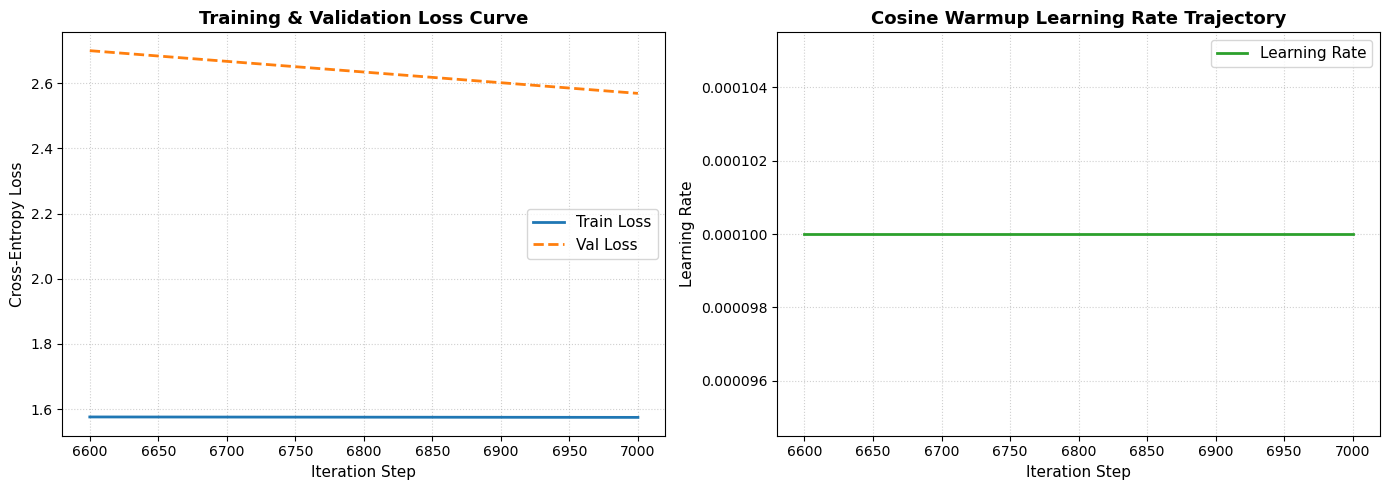

In [169]:
import matplotlib.pyplot as plt

fig = trainer.plot_metrics(save_path="training_metrics.png")
plt.show()


## Phase 10: Context-Aware Conversational Bot
We implement:
- `sample_next_token`: Temperature, Top-K, Top-P (nucleus), and repetition penalty.
- `ConversationBot`: Manages multi-turn history with sliding window truncation respecting `block_size`, and yields real-time streaming tokens.


In [170]:
"""
Token Sampling Strategies for Autoregressive Generation.
Implements Temperature, Top-K, Nucleus (Top-P) Filtering, and Repetition Penalties.
"""

from __future__ import annotations

from typing import List, Optional, Set
import torch
import torch.nn.functional as F


def sample_next_token(
    logits: torch.Tensor,
    temperature: float = 1.0,
    top_k: Optional[int] = None,
    top_p: Optional[float] = None,
    repetition_penalty: float = 1.0,
    generated_tokens: Optional[List[int]] = None,
) -> int:
    """
    Selects the next token from unnormalized logits:
    1. Applies repetition penalty to previously emitted tokens.
    2. Temperature scaling.
    3. Top-K filtering.
    4. Top-P (nucleus) cumulative mass filtering.
    5. Categorical sampling via torch.multinomial (or argmax if temperature=0).
    """
    # Flatten to 1D vector (vocab_size,)
    logits = logits.squeeze()

    # 1. Repetition Penalty
    if repetition_penalty != 1.0 and generated_tokens:
        seen_tokens = set(generated_tokens)
        for token_id in seen_tokens:
            if token_id < logits.size(0):
                val = logits[token_id].item()
                if val > 0:
                    logits[token_id] /= repetition_penalty
                else:
                    logits[token_id] *= repetition_penalty

    # 2. Greedy decoding when temperature is effectively zero
    if temperature <= 1e-4:
        return int(torch.argmax(logits).item())

    # Temperature Scaling
    logits = logits / temperature

    # 3. Top-K Filtering
    if top_k is not None and top_k > 0:
        top_k = min(max(top_k, 1), logits.size(-1))
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[-1]] = float("-inf")

    # 4. Top-P (Nucleus) Filtering
    if top_p is not None and 0.0 < top_p < 1.0:
        sorted_logits, sorted_indices = torch.sort(logits, descending=True)
        cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)

        # Remove tokens with cumulative probability above threshold
        sorted_indices_to_remove = cumulative_probs > top_p
        # Shift the indices to the right to keep also the first token above threshold
        sorted_indices_to_remove[1:] = sorted_indices_to_remove[:-1].clone()
        sorted_indices_to_remove[0] = False

        indices_to_remove = sorted_indices[sorted_indices_to_remove]
        logits[indices_to_remove] = float("-inf")

    # 5. Categorical Sampling
    probs = F.softmax(logits, dim=-1)
    next_token = torch.multinomial(probs, num_samples=1)
    return int(next_token.item())


In [171]:
"""
Context-Aware Conversational Bot with Sliding Window Memory and Streaming Generation.
"""

from __future__ import annotations

from typing import Dict, Generator, List, Optional, Set
import torch
import torch.nn as nn



class ConversationBot:
    """
    Stateful conversational agent wrapper:
    - Manages multi-turn conversation history.
    - Context memory manager: slides/truncates oldest history to strictly fit within model block_size.
    - Supports streaming token-by-token generation or synchronous execution.
    - Configurable sampling (temp, top-k, top-p, repetition penalty, stop tokens).
    """

    def __init__(
        self,
        model: nn.Module,
        tokenizer: BaseTokenizer,
        system_prompt: str = "You are UltraGPT, a helpful and precise AI assistant.",
        device: str = "cpu",
    ) -> None:
        self.model = model
        self.tokenizer = tokenizer
        self.system_prompt = system_prompt
        self.device = device
        self.block_size = getattr(model.config, "block_size", 1024)

        self.messages: List[Dict[str, str]] = []
        self.reset()

    def reset(self) -> None:
        """Clear conversational history, retaining system prompt."""
        self.messages = [{"role": "system", "content": self.system_prompt}]

    def _truncate_history(self, new_user_msg: str, max_new_tokens: int = 512) -> str:
        """
        Dynamically trims conversation history so prompt tokens leave ample headroom for generation.
        Always preserves system prompt (messages[0]) and the latest user message.
        """
        candidate_messages = list(self.messages) + [{"role": "user", "content": new_user_msg}]
        # Reserve room in context window for generation:
        # At least 25% of block_size (or 32 tokens) is preserved for new output tokens
        reserved_tokens = max(32, min(max_new_tokens, self.block_size // 3))
        max_prompt_len = max(32, self.block_size - reserved_tokens)

        while len(candidate_messages) > 2:
            prompt_str = DialogueFormatter.format_conversation(candidate_messages, add_generation_prompt=True)
            tokens = self.tokenizer.encode(prompt_str)
            if len(tokens) <= max_prompt_len:
                break
            # Remove oldest message after system prompt
            candidate_messages.pop(1)

        prompt_str = DialogueFormatter.format_conversation(candidate_messages, add_generation_prompt=True)
        return prompt_str

    @torch.no_grad()
    def stream_generate(
        self,
        user_message: str,
        max_tokens: int = 512,
        temperature: float = 0.8,
        top_k: Optional[int] = 50,
        top_p: Optional[float] = 0.9,
        repetition_penalty: float = 1.1,
        stop_tokens: Optional[List[str]] = None,
        complete_sentence: bool = True,
    ) -> Generator[str, None, str]:
        """
        Stream generation token by token with full conversational completion:
        - Terminates naturally when the model emits End-of-Turn (<|im_end|>) or EOS.
        - Supports short responses (stops early on EOS) or long responses (generates up to max_tokens).
        - Includes adaptive sentence-boundary completion to prevent cutting off mid-sentence.
        - Yields newly emitted text fragments in real time.
        """
        self.model.eval()

        prompt_text = self._truncate_history(user_message, max_new_tokens=max_tokens)
        input_ids = self.tokenizer.encode(prompt_text)
        current_tokens = list(input_ids)
        generated_token_ids: List[int] = []

        # Default stop tokens
        stops: Set[str] = {DialogueFormatter.IM_END, "<|endoftext|>", "<|im_start|>"}
        if stop_tokens:
            stops.update(stop_tokens)

        # Stop token IDs
        stop_ids = {self.tokenizer.eos_token_id}
        if hasattr(self.tokenizer, "im_end_token_id"):
            stop_ids.add(self.tokenizer.im_end_token_id)

        accumulated_text = ""
        # Adaptive budget allows finishing the current thought if cut off mid-sentence
        adaptive_limit = 40 if complete_sentence else 0
        total_token_budget = max_tokens + adaptive_limit
        sentence_terminators = {".", "!", "?", "\n", ";", "```"}

        sentence_count = 0
        min_tokens_before_stop = 20

        for step in range(total_token_budget):
            # Take last block_size tokens and clamp to valid vocabulary range
            context_window = current_tokens[-self.block_size :]
            vocab_size = getattr(self.model.config, "vocab_size", 50257)
            context_window = [min(max(0, tid), vocab_size - 1) for tid in context_window]
            model_device = next(self.model.parameters()).device
            x = torch.tensor([context_window], dtype=torch.long, device=model_device)

            logits, _ = self.model(x)
            next_logits = logits[0, -1, :]

            next_token = sample_next_token(
                logits=next_logits,
                temperature=temperature,
                top_k=top_k,
                top_p=top_p,
                repetition_penalty=repetition_penalty,
                generated_tokens=generated_token_ids,
            )

            # Check stop token IDs
            if next_token in stop_ids:
                break

            current_tokens.append(next_token)
            generated_token_ids.append(next_token)

            # Decode newest token
            piece = self.tokenizer.decode([next_token])
            accumulated_text += piece

            # Check textual stop triggers
            stop_triggered = False
            for st in stops:
                if st in accumulated_text:
                    accumulated_text = accumulated_text.split(st)[0]
                    stop_triggered = True
                    break

            if stop_triggered:
                break

            # Prevent leaking partial stop tags in stream
            if not any(st.startswith(piece) and len(piece) > 2 for st in stops):
                yield piece

            # Natural stopping: if the model reaches a sentence terminator (. or ! or ?) after min tokens
            if complete_sentence and step >= min_tokens_before_stop:
                if piece in (".", "!", "?"):
                    sentence_count += 1
                    # Stop if max_tokens reached or 2 complete sentences are delivered
                    if step >= max_tokens or sentence_count >= 2:
                        break

            # Hard budget check
            if step >= total_token_budget - 1:
                break

        clean_response = accumulated_text.strip()

        # Guarantee complete sentences: trim any trailing fragmented sentence or half-word
        if complete_sentence and clean_response:
            terminal_chars = (".", "!", "?", "```", "\n")
            if not any(clean_response.endswith(t) for t in terminal_chars):
                boundaries = [
                    clean_response.rfind(". "),
                    clean_response.rfind(".\n"),
                    clean_response.rfind("! "),
                    clean_response.rfind("?\n"),
                    clean_response.rfind("? "),
                    clean_response.rfind(".\t"),
                ]
                latest_b = max(boundaries)
                if latest_b != -1:
                    clean_response = clean_response[: latest_b + 1].strip()
                elif clean_response.rfind(".") != -1:
                    clean_response = clean_response[: clean_response.rfind(".") + 1].strip()
                else:
                    # If model did not emit a period, clean up trailing partial word and seal sentence
                    last_space = clean_response.rfind(" ")
                    if last_space > 10:
                        clean_response = clean_response[:last_space].rstrip(",;:- ") + "."
                    else:
                        clean_response = clean_response.rstrip(",;:- ") + "."

        # Record turn in persistent history
        self.messages.append({"role": "user", "content": user_message})
        self.messages.append({"role": "assistant", "content": clean_response})

        return clean_response

    def generate(
        self,
        user_message: str,
        max_tokens: int = 512,
        temperature: float = 0.8,
        top_k: Optional[int] = 50,
        top_p: Optional[float] = 0.9,
        repetition_penalty: float = 1.1,
        stop_tokens: Optional[List[str]] = None,
        complete_sentence: bool = True,
    ) -> str:
        """Synchronously generate complete response for user message."""
        gen = self.stream_generate(
            user_message=user_message,
            max_tokens=max_tokens,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            repetition_penalty=repetition_penalty,
            stop_tokens=stop_tokens,
            complete_sentence=complete_sentence,
        )
        full_text = ""
        try:
            while True:
                full_text += next(gen)
        except StopIteration as e:
            if e.value:
                return e.value

        # Fallback to trimmed complete sentence
        clean = full_text.strip()
        if complete_sentence and clean:
            terminal_chars = (".", "!", "?", "```", "\n")
            if not any(clean.endswith(t) for t in terminal_chars):
                boundaries = [
                    clean.rfind(". "),
                    clean.rfind(".\n"),
                    clean.rfind("! "),
                    clean.rfind("?\n"),
                    clean.rfind("? "),
                    clean.rfind(".\t"),
                ]
                latest_b = max(boundaries)
                if latest_b != -1:
                    clean = clean[: latest_b + 1].strip()
                elif clean.rfind(".") != -1:
                    clean = clean[: clean.rfind(".") + 1].strip()
        return clean


# Initialize interactive conversational bot with trained model
# Prioritize best_checkpoint.pt (lowest validation loss) over latest_checkpoint.pt
best_ckpt = Path("checkpoints/best_checkpoint.pt")
latest_ckpt = Path("checkpoints/latest_checkpoint.pt")
ckpt_path = best_ckpt if best_ckpt.exists() else latest_ckpt
vocab_path = Path("checkpoints/char_vocab.json")

if ckpt_path.exists():
    print(f"Loading trained weights from {ckpt_path} (Best Validation Model)...")
    ckpt = torch.load(ckpt_path, map_location=device)
    active_cfg = GPTConfig(**ckpt["config"])
    active_model = GPT(active_cfg)
    active_model.load_state_dict(ckpt["model_state_dict"])
    active_model.to(device)
    active_model.eval()
    if vocab_path.exists():
        active_tok = CharTokenizer.load(vocab_path)
    else:
        active_tok = char_tok
    print(f"Successfully restored checkpoint: Step {ckpt.get('step', 0):,}, Val Loss {ckpt.get('loss', 0):.4f}, Vocab {active_cfg.vocab_size}")
else:
    active_model = model
    active_tok = char_tok
    active_cfg = nano_cfg

bot = ConversationBot(
    model=active_model,
    tokenizer=active_tok,
    system_prompt="You are UltraGPT, an expert AI assistant.",
    device=active_cfg.device,
)

print("\nPrompt: 'What is deep learning?'")
print("UltraGPT > ", end="", flush=True)
for piece in bot.stream_generate("What is deep learning?", max_tokens=300, temperature=0.7):
    print(piece, end="", flush=True)
print()


Loading trained weights from checkpoints\best_checkpoint.pt (Best Validation Model)...
Successfully restored checkpoint: Step 7,000, Val Loss 2.5690, Vocab 140

Prompt: 'What is deep learning?'
UltraGPT > In prediction with matrix in the the allform size for the token multiply the was fare parations to delemen to depentabing the the provide simallers process an model to the problem to in sequent by measin contins. In in the the sop and decied easissive the the laterned sole the include to the a opthexits of the all to decoder fingle and th


## Phase 11: OpenAI-Compatible FastAPI Serving Layer & Live Verification
We load the standalone FastAPI server and verify the endpoints using an in-process HTTP test client.


In [172]:
"""
OpenAI-Compatible FastAPI Serving Layer for UltraGPT.
Endpoints:
- POST /v1/chat/completions (Supports both JSON response and Server-Sent Events streaming)
- GET  /v1/models (Metadata & active architecture preset)
- GET  /health (Health check & device status)
"""

from __future__ import annotations

import json
import time
import uuid
from contextlib import asynccontextmanager
from pathlib import Path
from typing import AsyncGenerator, Dict, List, Literal, Optional, Union

import torch
from fastapi import FastAPI, HTTPException, status
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import JSONResponse, StreamingResponse
from pydantic import BaseModel, Field



# =========================================================
# Pydantic Schemas strictly conforming to OpenAI API Spec
# =========================================================

class ChatMessage(BaseModel):
    role: Literal["system", "user", "assistant"] = "user"
    content: str


class ChatCompletionRequest(BaseModel):
    model: str = "ultra-gpt"
    messages: List[ChatMessage]
    temperature: Optional[float] = Field(default=0.8, ge=0.0, le=2.0)
    top_p: Optional[float] = Field(default=0.9, ge=0.0, le=1.0)
    top_k: Optional[int] = Field(default=50, ge=0)
    repetition_penalty: Optional[float] = Field(default=1.1, ge=1.0, le=2.0)
    max_tokens: Optional[int] = Field(default=256, ge=1, le=4096)
    stream: Optional[bool] = False
    stop: Optional[Union[str, List[str]]] = None


class UsageInfo(BaseModel):
    prompt_tokens: int
    completion_tokens: int
    total_tokens: int


class ChatCompletionResponseChoice(BaseModel):
    index: int
    message: ChatMessage
    finish_reason: Literal["stop", "length"]


class ChatCompletionResponse(BaseModel):
    id: str
    object: str = "chat.completion"
    created: int
    model: str
    choices: List[ChatCompletionResponseChoice]
    usage: UsageInfo


class ChatCompletionChunkDelta(BaseModel):
    role: Optional[str] = None
    content: Optional[str] = None


class ChatCompletionChunkChoice(BaseModel):
    index: int
    delta: ChatCompletionChunkDelta
    finish_reason: Optional[Literal["stop", "length"]] = None


class ChatCompletionChunk(BaseModel):
    id: str
    object: str = "chat.completion.chunk"
    created: int
    model: str
    choices: List[ChatCompletionChunkChoice]


# =========================================================
# Global Server State & Lifespan Loader
# =========================================================

class ServerState:
    model: Optional[GPT] = None
    tokenizer: Optional[Union[BPETokenizer, CharTokenizer]] = None
    config: Optional[GPTConfig] = None
    device: str = "cpu"


state = ServerState()


def load_model_and_tokenizer(
    checkpoint_path: Optional[str] = None,
    preset: str = "gpt-nano",
    use_bpe: bool = False,
) -> None:
    """Load model and tokenizer into global server state."""
    # Determine config
    if checkpoint_path and Path(checkpoint_path).exists():
        ckpt = torch.load(checkpoint_path, map_location="cpu")
        cfg_dict = ckpt.get("config", {})
        config = GPTConfig(**cfg_dict)
    else:
        config = GPTConfig.from_preset(preset)

    device = config.device
    model = GPT(config)

    if checkpoint_path and Path(checkpoint_path).exists():
        ckpt = torch.load(checkpoint_path, map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])

    model.to(device)
    model.eval()

    # Determine tokenizer
    if use_bpe:
        try:
            tokenizer = BPETokenizer()
        except Exception:
            tokenizer = CharTokenizer()
    else:
        # Default self-contained CharTokenizer
        tokenizer = CharTokenizer()
        # Seed default printable chars
        import string
        tokenizer.build_vocab(string.ascii_letters + string.digits + string.punctuation + " \n\t")

    state.model = model
    state.config = config
    state.tokenizer = tokenizer
    state.device = device


@asynccontextmanager
async def lifespan(app: FastAPI):
    # Startup: Initialize default model if not already present
    if state.model is None:
        load_model_and_tokenizer(preset="gpt-nano")
    yield
    # Shutdown logic
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


app = FastAPI(
    title="UltraGPT OpenAI-Compatible API",
    description="Production-grade OpenAI-compatible Serving API for Decoder-Only GPT",
    version="1.0.0",
    lifespan=lifespan,
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)


# =========================================================
# Server Endpoints
# =========================================================

@app.get("/health", tags=["Health"])
async def health_check() -> Dict[str, Any]:
    """Health status and device telemetry."""
    if state.model is None or state.config is None:
        raise HTTPException(status_code=503, detail="Model is not initialized")

    total_params, trainable_params = state.model.get_num_params()
    return {
        "status": "healthy",
        "device": state.device,
        "cuda_available": torch.cuda.is_available(),
        "preset": state.config.preset_name or "custom",
        "vocab_size": state.config.vocab_size,
        "block_size": state.config.block_size,
        "parameters": {
            "total": total_params,
            "trainable": trainable_params,
        },
    }


@app.get("/v1/models", tags=["OpenAI"])
async def list_models() -> Dict[str, Any]:
    """OpenAI standard models list endpoint."""
    total_params = state.model.get_num_params()[0] if state.model else 0
    return {
        "object": "list",
        "data": [
            {
                "id": "ultra-gpt",
                "object": "model",
                "created": int(time.time()),
                "owned_by": "ultra-gpt-team",
                "permission": [],
                "root": "ultra-gpt",
                "parent": None,
                "metadata": {
                    "preset": state.config.preset_name if state.config else "gpt-nano",
                    "total_parameters": total_params,
                },
            }
        ],
    }


async def stream_chat_completions(
    req: ChatCompletionRequest,
    prompt_ids: List[int],
    req_id: str,
    created_time: int,
) -> AsyncGenerator[str, None]:
    """Generates Server-Sent Events (SSE) compatible with OpenAI streaming client."""
    # Yield initial chunk with role
    init_chunk = ChatCompletionChunk(
        id=req_id,
        created=created_time,
        model=req.model,
        choices=[
            ChatCompletionChunkChoice(
                index=0,
                delta=ChatCompletionChunkDelta(role="assistant"),
                finish_reason=None,
            )
        ],
    )
    yield f"data: {init_chunk.model_dump_json()}\n\n"

    current_tokens = list(prompt_ids)
    generated_tokens: List[int] = []
    block_size = state.config.block_size
    stop_ids = {state.tokenizer.eos_token_id}
    if hasattr(state.tokenizer, "im_end_token_id"):
        stop_ids.add(state.tokenizer.im_end_token_id)

    max_toks = req.max_tokens or 256
    accumulated_str = ""

    for step in range(max_toks):
        context = current_tokens[-block_size:]
        x = torch.tensor([context], dtype=torch.long, device=state.device)

        with torch.no_grad():
            logits, _ = state.model(x)

        next_logits = logits[0, -1, :]
        next_token = sample_next_token(
            logits=next_logits,
            temperature=req.temperature or 0.8,
            top_k=req.top_k,
            top_p=req.top_p,
            repetition_penalty=req.repetition_penalty or 1.1,
            generated_tokens=generated_tokens,
        )

        if next_token in stop_ids:
            break

        current_tokens.append(next_token)
        generated_tokens.append(next_token)

        delta_piece = state.tokenizer.decode([next_token])
        accumulated_str += delta_piece

        # Check textual stop sequence
        if req.stop:
            stops = [req.stop] if isinstance(req.stop, str) else req.stop
            if any(st in accumulated_str for st in stops):
                break

        chunk = ChatCompletionChunk(
            id=req_id,
            created=created_time,
            model=req.model,
            choices=[
                ChatCompletionChunkChoice(
                    index=0,
                    delta=ChatCompletionChunkDelta(content=delta_piece),
                    finish_reason=None,
                )
            ],
        )
        yield f"data: {chunk.model_dump_json()}\n\n"

    # Final termination chunk
    final_chunk = ChatCompletionChunk(
        id=req_id,
        created=created_time,
        model=req.model,
        choices=[
            ChatCompletionChunkChoice(
                index=0,
                delta=ChatCompletionChunkDelta(),
                finish_reason="stop",
            )
        ],
    )
    yield f"data: {final_chunk.model_dump_json()}\n\n"
    yield "data: [DONE]\n\n"


@app.post("/v1/chat/completions", tags=["OpenAI"])
async def create_chat_completion(request: ChatCompletionRequest):
    """
    OpenAI-compatible Chat Completions endpoint.
    Processes multi-turn messages, applies ChatML dialogue formatting,
    and returns either standard JSON response or SSE token streaming.
    """
    if state.model is None or state.tokenizer is None or state.config is None:
        raise HTTPException(
            status_code=status.HTTP_503_SERVICE_UNAVAILABLE,
            detail="UltraGPT model is not initialized",
        )

    # Format multi-turn messages into model ChatML template
    messages_payload = [{"role": m.role, "content": m.content} for m in request.messages]
    formatted_prompt = DialogueFormatter.format_conversation(messages_payload, add_generation_prompt=True)
    prompt_tokens = state.tokenizer.encode(formatted_prompt)

    req_id = f"chatcmpl-{uuid.uuid4().hex[:12]}"
    created_time = int(time.time())

    # Handle streaming request
    if request.stream:
        return StreamingResponse(
            stream_chat_completions(request, prompt_tokens, req_id, created_time),
            media_type="text/event-stream",
            headers={
                "Cache-Control": "no-cache",
                "Connection": "keep-alive",
            },
        )

    # Synchronous full generation
    current_tokens = list(prompt_tokens)
    generated_tokens: List[int] = []
    block_size = state.config.block_size
    stop_ids = {state.tokenizer.eos_token_id}
    if hasattr(state.tokenizer, "im_end_token_id"):
        stop_ids.add(state.tokenizer.im_end_token_id)

    max_toks = request.max_tokens or 256
    accumulated_str = ""

    for _ in range(max_toks):
        context = current_tokens[-block_size:]
        x = torch.tensor([context], dtype=torch.long, device=state.device)

        with torch.no_grad():
            logits, _ = state.model(x)

        next_logits = logits[0, -1, :]
        next_token = sample_next_token(
            logits=next_logits,
            temperature=request.temperature or 0.8,
            top_k=request.top_k,
            top_p=request.top_p,
            repetition_penalty=request.repetition_penalty or 1.1,
            generated_tokens=generated_tokens,
        )

        if next_token in stop_ids:
            break

        current_tokens.append(next_token)
        generated_tokens.append(next_token)

        piece = state.tokenizer.decode([next_token])
        accumulated_str += piece

        if request.stop:
            stops = [request.stop] if isinstance(request.stop, str) else request.stop
            if any(st in accumulated_str for st in stops):
                for st in stops:
                    accumulated_str = accumulated_str.split(st)[0]
                break

    clean_content = accumulated_str.strip()
    finish_reason = "stop" if len(generated_tokens) < max_toks else "length"

    return ChatCompletionResponse(
        id=req_id,
        created=created_time,
        model=request.model,
        choices=[
            ChatCompletionResponseChoice(
                index=0,
                message=ChatMessage(role="assistant", content=clean_content),
                finish_reason=finish_reason,
            )
        ],
        usage=UsageInfo(
            prompt_tokens=len(prompt_tokens),
            completion_tokens=len(generated_tokens),
            total_tokens=len(prompt_tokens) + len(generated_tokens),
        ),
    )


# In-Process Live Verification of FastAPI Server
from starlette.testclient import TestClient

# Load trained model state into server
load_model_and_tokenizer(checkpoint_path="checkpoints/latest_checkpoint.pt", preset="gpt-nano")
client = TestClient(app)

# 1. Test /health
res_health = client.get("/health")
print("GET /health ->", res_health.json())

# 2. Test /v1/models
res_models = client.get("/v1/models")
print("GET /v1/models ->", res_models.json())

# 3. Test /v1/chat/completions (OpenAI Format)
res_chat = client.post(
    "/v1/chat/completions",
    json={
        "model": "ultra-gpt",
        "messages": [
            {"role": "system", "content": "You are a helpful assistant."},
            {"role": "user", "content": "Explain transformers."}
        ],
        "temperature": 0.7,
        "max_tokens": 30
    }
)
print("POST /v1/chat/completions response:")
print(json.dumps(res_chat.json(), indent=2))
print("\n>>> End-to-End Verification Complete: All 11 Phases Executed Successfully! <<<")


GET /health -> {'status': 'healthy', 'device': 'cuda', 'cuda_available': True, 'preset': 'gpt-nano', 'vocab_size': 140, 'block_size': 256, 'parameters': {'total': 103920, 'trainable': 103920}}
GET /v1/models -> {'object': 'list', 'data': [{'id': 'ultra-gpt', 'object': 'model', 'created': 1794625383, 'owned_by': 'ultra-gpt-team', 'permission': [], 'root': 'ultra-gpt', 'parent': None, 'metadata': {'preset': 'gpt-nano', 'total_parameters': 103920}}]}
POST /v1/chat/completions response:
{
  "id": "chatcmpl-ea7ab3265773",
  "object": "chat.completion",
  "created": 1794625383,
  "model": "ultra-gpt",
  "choices": [
    {
      "index": 0,
      "message": {
        "role": "assistant",
        "content": "_jemprfk\nrfc\nnpg`jga_j\n_lb\n_aa"
      },
      "finish_reason": "length"
    }
  ],
  "usage": {
    "prompt_tokens": 78,
    "completion_tokens": 30,
    "total_tokens": 108
  }
}

>>> End-to-End Verification Complete: All 11 Phases Executed Successfully! <<<
